In [24]:
## LAI Analysis and scaling in Fynbos using multi platform-based Data (UAS-MSI + AVIRIS-NG HSI data)
## Author: Ramesh Bhatta, CIS, RIT
## Contact: rb1005@rit.edu

"""
This code file is intended to be used for UAS+AVIRIS-NG LAI modeling and analysis in fire-prone low-stature shurblands present in CFR, SA.
It also tests the integration of both datasets (i.e. Cross-sensor harmonization) for improved modeling accuracy.
"""

## Imorting necessary libraries
import re
import os
import warnings
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
import folium

import rasterio
from rasterio.plot import show
from rasterio.windows import Window
from rasterio.mask import mask
from rasterio.merge import merge
from rasterstats import zonal_stats


import geopandas as gpd
from shapely.ops import transform
from shapely.geometry import Point, box, Polygon

from netCDF4 import Dataset

from scipy import stats
from scipy.stats import linregress, pearsonr, skew
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

import statsmodels.api as sm

from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import LeaveOneOut, train_test_split
from sklearn.linear_model import LinearRegression, RANSACRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures

# Set the current working directory: same as the location of notebook
os.chdir(os.getcwd())

In [25]:
## Predefined plot preferences

# Define text sizes
SMALL_SIZE = 14
MEDIUM_SIZE = 16
BIGGER_SIZE = 18

# Apply text size settings
font = {'family': 'serif'}  # Serif font style
plt.rc('font', **font)
plt.rc('font', size=SMALL_SIZE)          # Default font size
plt.rc('axes', titlesize=MEDIUM_SIZE)   # Axis title font size
plt.rc('axes', labelsize=MEDIUM_SIZE)   # Axis labels font size
plt.rc('xtick', labelsize=SMALL_SIZE)   # X-axis tick label font size
plt.rc('ytick', labelsize=SMALL_SIZE)   # Y-axis tick label font size
plt.rc('legend', fontsize=SMALL_SIZE)   # Legend font size
plt.rc('figure', titlesize=BIGGER_SIZE) # Figure title font size

In [26]:
"""

A. Modeling LAI using drone-based multispectral data: Here we are using just 4 band drone based indices to model the plot-level LAI data. 
The total test samples available are 11 so we will need to check robustness of the model carefully.

"""
## A1. Read the drone-based multispectral data from tif files: Bands = [G, R, RE, NIR]

BY2006_file_path = "./Drone_msi_data/burn2006_lr_band_stack.tif"
BY2016_file_path = "./Drone_msi_data/burn2016_lr_band_stack.tif"
BY2019_file_path = "./Drone_msi_data/burn2019_lr_band_stack.tif"
BY2020_file_path = "./Drone_msi_data/burn2020_lr_band_stack.tif"
BY2017_2016_file_path = "./Drone_msi_data/burn2017_2016_lr_band_stack.tif"

# Map the names to the actual file paths
file_map = {
    "BY_2006": BY2006_file_path,
    "BY_2016": BY2016_file_path,
    "BY_2019": BY2019_file_path,
    "BY_2020": BY2020_file_path,
    "BY_2017_16": BY2017_2016_file_path
}

# Create a dictionary to store the numerical data
msi_datasets = {}

for name, path in file_map.items():
    with rasterio.open(path) as src:
        msi_datasets[name] = src.read()
        print(f"Loaded {name}: Shape {msi_datasets[name].shape}")


Loaded BY_2006: Shape (4, 6405, 5886)
Loaded BY_2016: Shape (4, 7844, 6972)
Loaded BY_2019: Shape (4, 7420, 6730)
Loaded BY_2020: Shape (4, 8353, 7589)
Loaded BY_2017_16: Shape (4, 7855, 7152)


In [27]:
## Print the crs of the msi dataset
with rasterio.open(BY2006_file_path) as src:
    print(f"CRS of BY2006 dataset: {src.crs}")

CRS of BY2006 dataset: EPSG:32734


In [28]:
## A2. Extract spectra corresponding to the field LAI measurement locations

import geopandas as gpd

LAI_measurement_shapefile = './ground_LAI_data_processed/5mx5m_LAI_plots.shp'
lai_gdf = gpd.read_file(LAI_measurement_shapefile)
print(lai_gdf.head())

   plot_id  LAI_mean    LAI_sd  n_reps   lon_mean   lat_mean  \
0  GBS0619  2.112576  0.371472       3  19.417133 -34.531937   
1  GBS0622  2.348314  0.658946       3  19.416763 -34.532163   
2  GBS0625  1.575255  0.150760       3  19.416767 -34.531720   
3  GBS0626  1.790895  0.190132       3  19.417487 -34.532730   
4  GBS0627  1.413221  0.461606       3  19.416707 -34.532463   

                                            geometry  
0  POLYGON ((354738.981 6177726.267, 354738.981 6...  
1  POLYGON ((354705.416 6177700.597, 354705.416 6...  
2  POLYGON ((354704.952 6177749.769, 354704.952 6...  
3  POLYGON ((354772.788 6177638.792, 354772.788 6...  
4  POLYGON ((354700.736 6177667.245, 354700.736 6...  


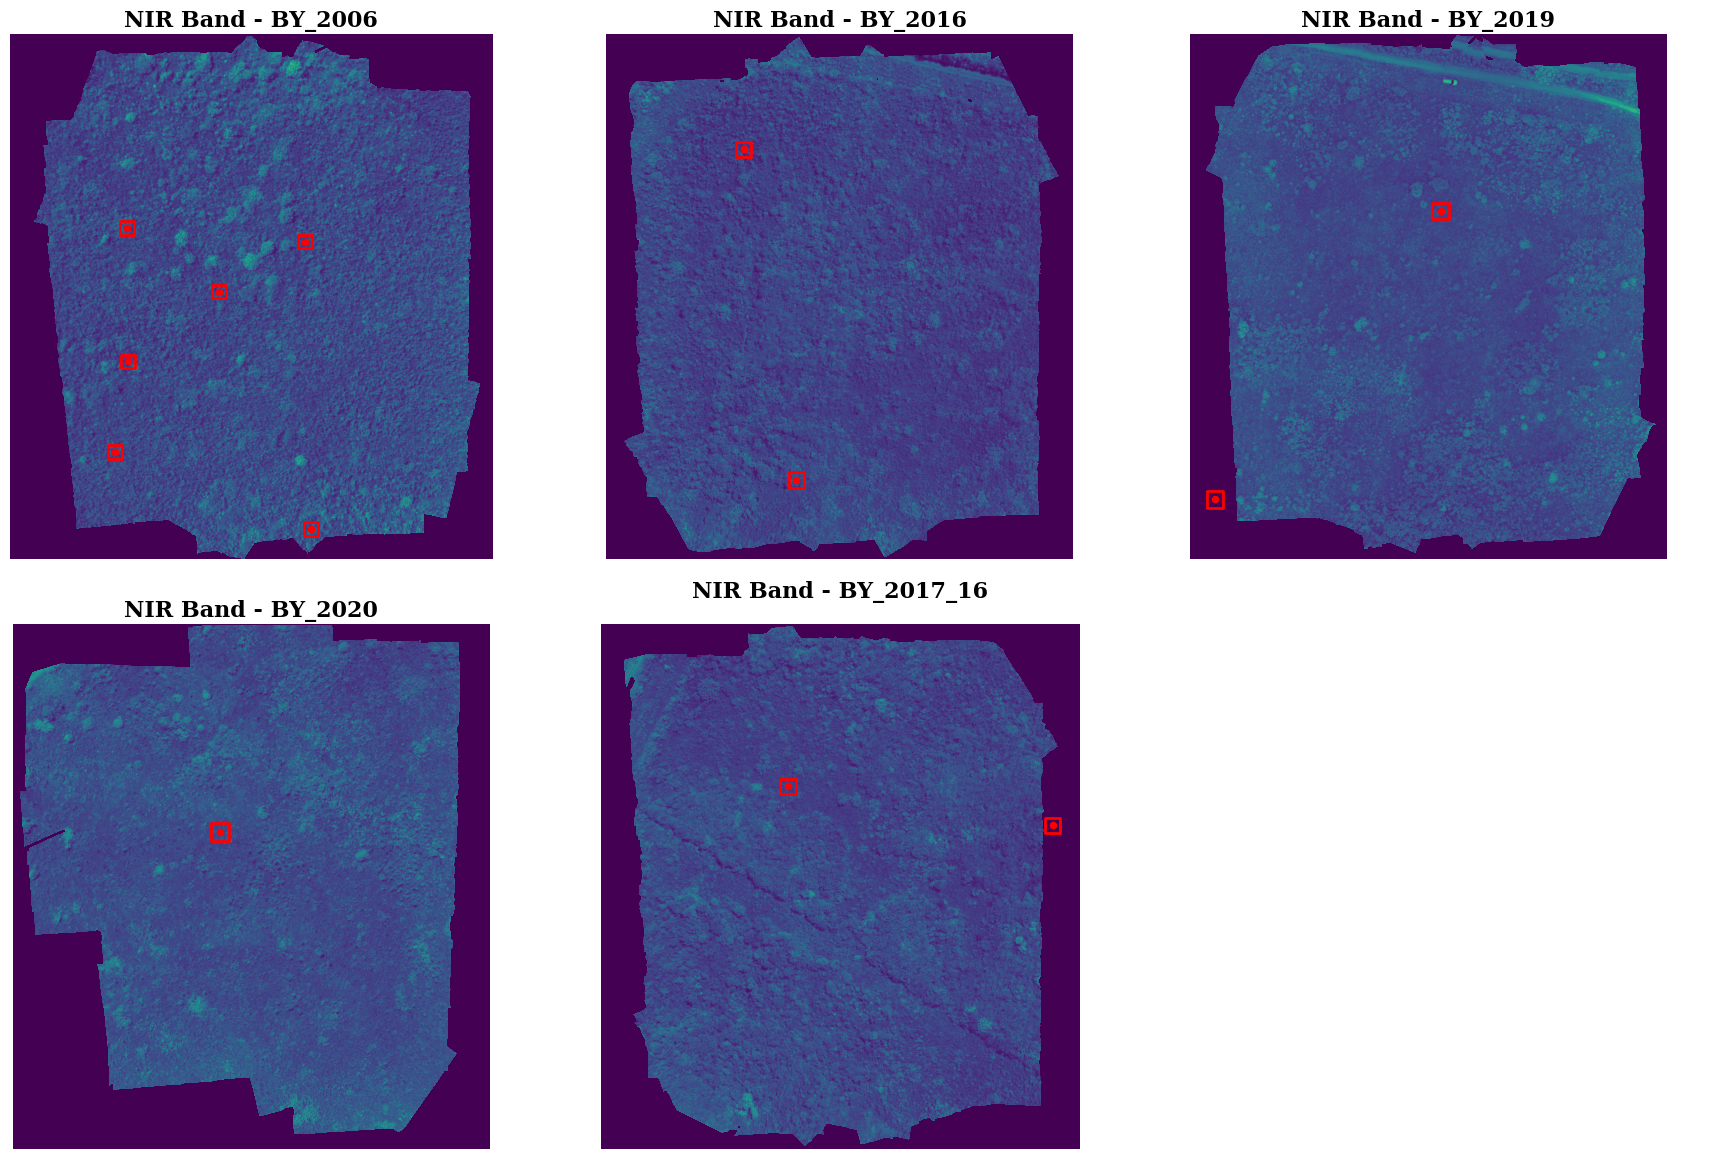

In [29]:
## A3. Plot the LAI measurement locations on top of the NIR band

# Create the subplot grid
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes_flat = axes.flatten()

for i, (name, path) in enumerate(file_map.items()):
    ax = axes_flat[i]
    
    with rasterio.open(path) as src:
        #  Rasterio's show function correctly applies the real-world spatial coordinates to the axes
        show((src, 4), ax=ax, cmap='viridis', title=f"NIR Band - {name}", vmin=0, vmax=1)
        
        # Ensure the shapefile CRS matches this specific raster
        if lai_gdf.crs != src.crs:
            gdf_plot = lai_gdf.to_crs(src.crs)
        else:
            gdf_plot = lai_gdf.copy()
        
        # Plot the LAI boundaries
        gdf_plot.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2)
        gdf_plot.centroid.plot(ax=ax, color='red', markersize=20)
        bounds = src.bounds
        ax.set_xlim(bounds.left, bounds.right)
        ax.set_ylim(bounds.bottom, bounds.top)
        ax.axis('off')

# Remove unsed subplots
for j in range(len(file_map), len(axes_flat)):
    axes_flat[j].axis('off')
plt.tight_layout()
plt.show()

In [30]:
## A5.(a) Extract the spectra where LAI is available

band_names = ['G', 'R', 'RE', 'NIR']

# results initialization
extracted_data = []

for name, path in file_map.items():
    print(f"Extracting spectra from {name}...")
    
    with rasterio.open(path) as src:
        raster_crs = src.crs
        
        # Ensure shapefile and raster have the same projection
        if lai_gdf.crs != raster_crs:
            print(f"  Reprojecting shapefile to match {name} CRS: {raster_crs}")
            gdf_proj = lai_gdf.to_crs(raster_crs)
        else:
            gdf_proj = lai_gdf.copy()
            
        # Iterate through each LAI plot
        for idx, row in gdf_proj.iterrows():
            geom = [row['geometry']]
            
            try:
                # Crop the raster to the polygon boundary
                out_image, out_transform = mask(src, geom, crop=True, filled=False)
                
                # Calculate the average spectrum for this polygon
                # out_image shape is (bands, rows, columns). 
                # We average over rows & cols (axis 1 and 2)
                mean_spectra = out_image.mean(axis=(1, 2))
                
                # Store the results 
                result_row = {
                    'plot_id': row['plot_id'],
                    'LAI_mean': row['LAI_mean'],
                    'dataset': name
                }
                
                # Add the 4 bands to our dictionary
                for b_idx, b_name in enumerate(band_names):
                    result_row[b_name] = mean_spectra[b_idx].item() 
                    
                extracted_data.append(result_row)
                
            except ValueError:
                pass

# Convert the compiled list of dictionaries into a DataFrame
final_spectra_df = pd.DataFrame(extracted_data)

# Remove the samples where all bands are zero i.e. which are in no-data areas near the edges of the rasters
final_spectra_df = final_spectra_df[~((final_spectra_df['G'] == 0) & 
                                        (final_spectra_df['R'] == 0) & 
                                        (final_spectra_df['RE'] == 0) & 
                                        (final_spectra_df['NIR'] == 0))]

print("Extraction complete!")

# Rename 'GBS17' plot_id as 'GBS16N' and burn year from 'BY_2017_16' to 'BY_2016': since the naming was confused
final_spectra_df['plot_id'] = final_spectra_df['plot_id'].replace('GBS17', 'GBS16N')
final_spectra_df['dataset'] = final_spectra_df['dataset'].replace('BY_2017_16', 'BY_2016')

print(final_spectra_df)


# Create a copy of dataframe for use in later sections where i do AVIRIS-based modeling and comparison
drone_modeling_df = final_spectra_df.copy()


Extracting spectra from BY_2006...
Extracting spectra from BY_2016...
Extracting spectra from BY_2019...
Extracting spectra from BY_2020...
Extracting spectra from BY_2017_16...
Extraction complete!
    plot_id  LAI_mean  dataset         G         R        RE       NIR
0   GBS0619  2.112576  BY_2006  0.034161  0.034532  0.089342  0.212260
1   GBS0622  2.348314  BY_2006  0.028595  0.027994  0.071307  0.209491
2   GBS0625  1.575255  BY_2006  0.024738  0.018641  0.075940  0.249230
3   GBS0626  1.790895  BY_2006  0.017204  0.017561  0.035050  0.236888
4   GBS0627  1.413221  BY_2006  0.023400  0.021833  0.066957  0.232795
5    GBS06P  1.977499  BY_2006  0.031670  0.032257  0.078149  0.210295
6    GBS164  1.737210  BY_2016  0.038887  0.031115  0.108350  0.221862
7    GBS16P  0.704166  BY_2016  0.041246  0.037990  0.102261  0.181714
9    GBS19P  1.133654  BY_2019  0.038490  0.033197  0.096021  0.207851
10   GBS20P  2.160475  BY_2020  0.038763  0.043396  0.099316  0.227874
12   GBS16N  1.41526

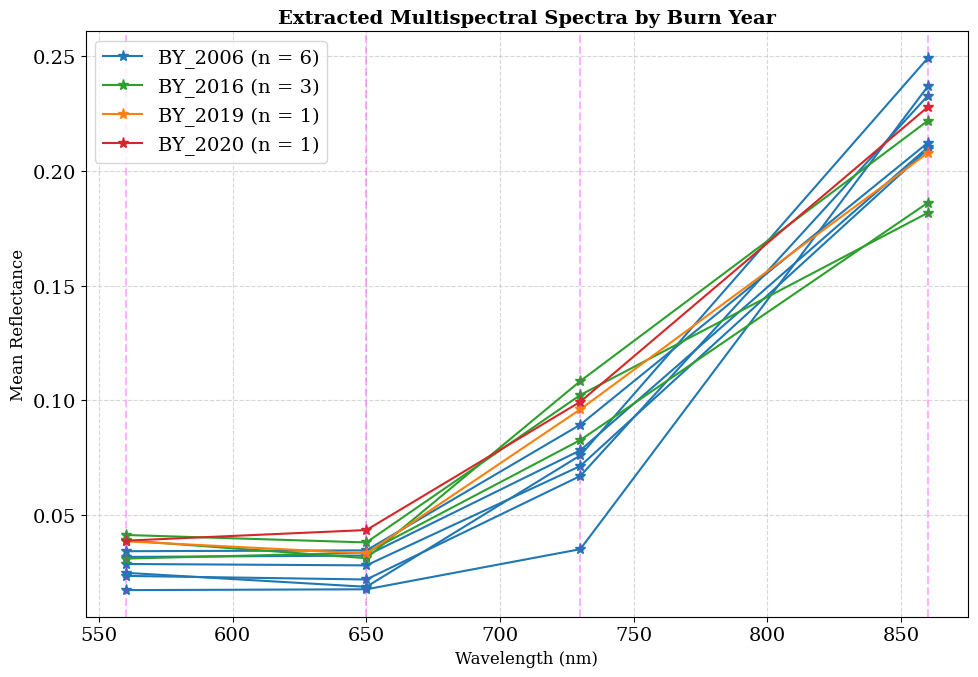

In [31]:
## A6. Plot all the extracted spectra (wavelength vs reflectance)

# Color mapping
color_mapping = {
    'BY_2006': '#1f77b4',       # Blue
    'BY_2016': '#2ca02c',       # Green
    'BY_2019': '#ff7f0e',       # Orange
    'BY_2020': '#d62728',       # Red
}

# 1. Pre-calculate sample counts for the labels
counts = final_spectra_df['dataset'].value_counts()

plt.figure(figsize=(10, 7))
wavelengths = [560, 650, 730, 860]

# Get unique datasets
dataset_names = final_spectra_df['dataset'].unique()

for name in dataset_names:
    subset = final_spectra_df[final_spectra_df['dataset'] == name]
    plot_color = color_mapping.get(name, 'black') 
    
    # 2. Create the dynamic label with n count
    n_count = counts[name]
    formatted_label = f"{name} (n = {n_count})"
    
    # Flag to label only once per year
    first_plot = True
    
    for idx, row in subset.iterrows():
        reflectance = [row['G'], row['R'], row['RE'], row['NIR']]
        
        # Label only once
        current_label = formatted_label if first_plot else None
        
        plt.plot(
            wavelengths, 
            reflectance, 
            marker='*',
            markersize=8, 
            color=plot_color, 
            alpha=1,               
            label=current_label,
            linewidth=1.5
        )
        first_plot = False 

# Vertical lines for band centers
for wl in wavelengths:
    plt.axvline(x=wl, color='magenta', linestyle='--', alpha=0.3)

plt.xlabel("Wavelength (nm)", fontsize=12)
plt.ylabel("Mean Reflectance", fontsize=12)
plt.title("Extracted Multispectral Spectra by Burn Year", fontsize=14, fontweight='bold')
plt.legend(loc='upper left', fontsize='medium', frameon=True, shadow=False)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [32]:
## A7. Calculate Important Vegetation Indices (VIs) for LAI modeling

df = final_spectra_df.copy()

# Extract bands into variables for cleaner math
G = df['G']
R = df['R']
RE = df['RE']
NIR = df['NIR']

## 1. Standard / Broad-band Indices
df['NDVI'] = (NIR - R) / (NIR + R)
df['SR'] = NIR / R
df['GNDVI'] = (NIR - G) / (NIR + G)
df['GRVI'] = (G - R) / (G + R)  # Green-Red Vegetation Index after Motohka et al. (2010)
df['GDVI'] = NIR - G            # Green-band difference metric

## 2. Soil-Adjusted Indices
df['SAVI'] = ((NIR - R) / (NIR + R + 0.5)) * 1.5
df['GSAVI'] = ((NIR - G) / (NIR + G + 0.5)) * 1.5  # Green-band SAVI adaptation
df['OSAVI'] = ((NIR - R) / (NIR + R + 0.16)) * 1.16
df['MSAVI2'] = 0.5 * (2 * NIR + 1 - np.sqrt((2 * NIR + 1)**2 - 8 * (NIR - R)))

## 3. Red-Edge Indices
df['NDRE'] = (NIR - RE) / (NIR + RE)
df['SR_RE'] = NIR / RE
df['CI_RE'] = (NIR / RE) - 1
df['MTCI'] = (NIR - RE) / (RE - R)  # MTCI-type index adapted to UAS red, red-edge, and NIR bands

## 4. Complex / Non-linear Indices
df['MSR'] = ((NIR / R) - 1) / (np.sqrt(NIR / R) + 1)
df['EVI2'] = 2.5 * (NIR - R) / (NIR + 2.4 * R + 1)
df['NIRv'] = df['NDVI'] * NIR
df['MTVI2'] = (1.5 * (1.2 * (NIR - G) - 2.5 * (R - G))) / (
    np.sqrt((2 * NIR + 1)**2 - (6 * NIR - 5 * np.sqrt(R)) - 0.5))

# Reassign back to the main dataframe
final_spectra_df = df
print("Calculated VIs successfully! Current columns:")
print(final_spectra_df.columns.tolist())

Calculated VIs successfully! Current columns:
['plot_id', 'LAI_mean', 'dataset', 'G', 'R', 'RE', 'NIR', 'NDVI', 'SR', 'GNDVI', 'GRVI', 'GDVI', 'SAVI', 'GSAVI', 'OSAVI', 'MSAVI2', 'NDRE', 'SR_RE', 'CI_RE', 'MTCI', 'MSR', 'EVI2', 'NIRv', 'MTVI2']


Correlation of each metric with LAI_mean: FULL metric set
NIR       0.385395
GSAVI     0.380707
GDVI      0.377955
GNDVI     0.350211
NDRE      0.328563
SAVI      0.280344
EVI2      0.274848
MSAVI2    0.264656
NIRv      0.260551
OSAVI     0.248187
MTCI      0.197771
SR_RE     0.193902
CI_RE     0.193902
NDVI      0.176076
MTVI2     0.161950
MSR       0.097014
SR        0.071726
R        -0.017228
RE       -0.233197
G        -0.234457
GRVI     -0.369850
Name: LAI_mean, dtype: float64

Retained non-redundant metrics for modeling:
['NIR', 'GSAVI', 'GDVI', 'GRVI', 'GNDVI', 'NDRE', 'SAVI', 'EVI2', 'MSAVI2', 'NIRv', 'OSAVI', 'G', 'RE', 'MTCI', 'SR_RE', 'CI_RE', 'NDVI', 'MTVI2', 'MSR', 'SR', 'R']

Dropped redundant metrics:
No metrics were dropped at the selected redundancy threshold.

Metrics selected for modeling:
['NIR', 'GSAVI', 'GDVI', 'GRVI', 'GNDVI', 'NDRE', 'SAVI', 'EVI2', 'MSAVI2', 'NIRv', 'OSAVI', 'G', 'RE', 'MTCI', 'SR_RE', 'CI_RE', 'NDVI', 'MTVI2', 'MSR', 'SR', 'R', 'LAI_mean']


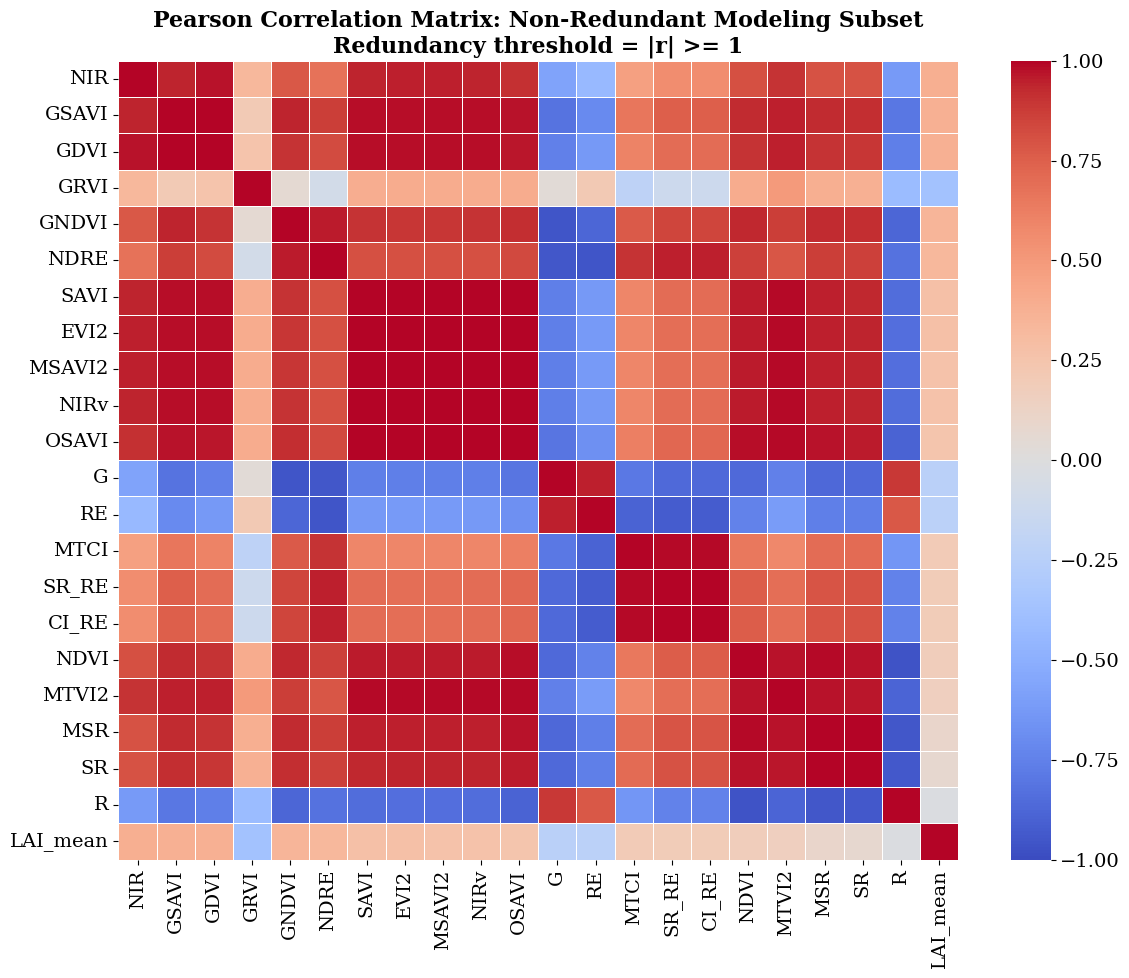

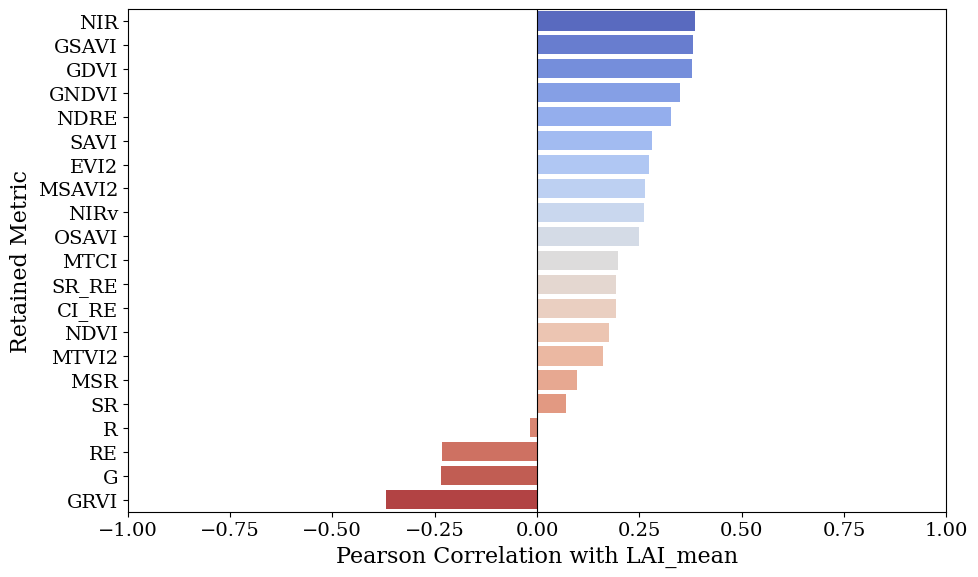

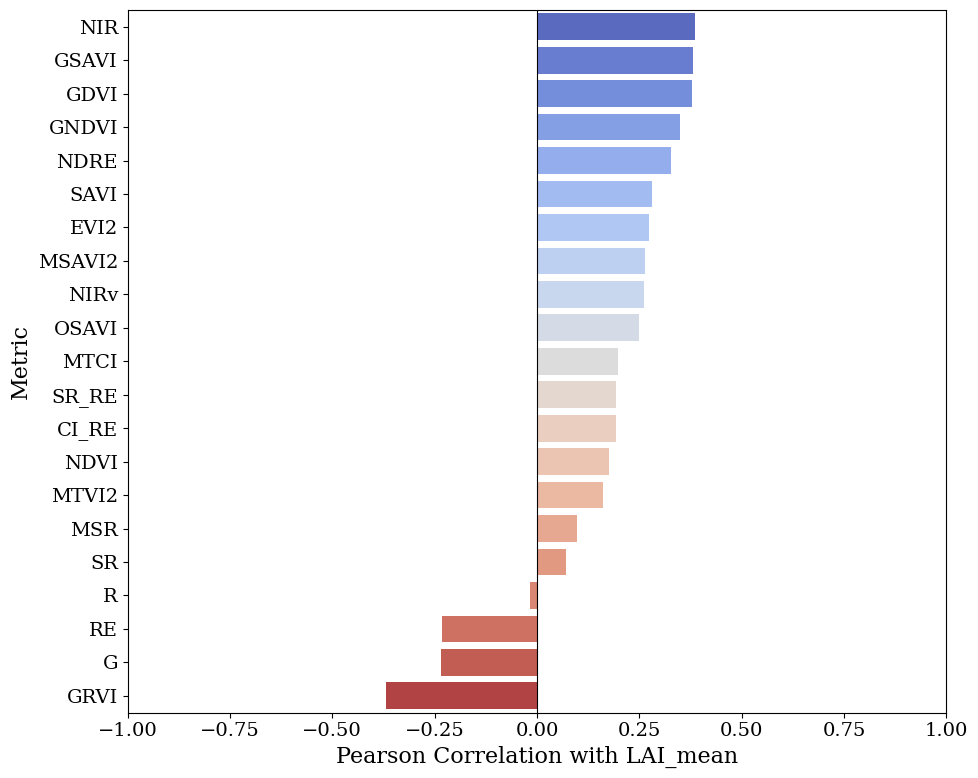

In [33]:
## A8. List metrics and their correlation with LAI
##  Create both full and non-redundant metric sets

redundancy_threshold = 1 # "CORRELATION THRESHOLD"

# 1. Prepare numeric metric dataframe
numeric_df = (
    final_spectra_df
    .select_dtypes(include=[np.number])
    .replace([np.inf, -np.inf], np.nan)
    .copy()
)

metric_cols = [col for col in numeric_df.columns if col != 'LAI_mean']

full_modeling_df = numeric_df[metric_cols + ['LAI_mean']].copy()

# 2. Full LAI correlations: 
full_corr_matrix = full_modeling_df.corr(numeric_only=True)

lai_correlations_full = (
    full_corr_matrix['LAI_mean']
    .drop('LAI_mean')
    .dropna()
    .sort_values(ascending=False)
)

print("Correlation of each metric with LAI_mean: FULL metric set")
print(lai_correlations_full)

# 3. Remove highly redundant metrics
metric_corr_abs = full_modeling_df[metric_cols].corr(numeric_only=True).abs()

# Keep metrics in order of strongest absolute relationship with LAI
metrics_by_lai_strength = (
    lai_correlations_full
    .abs()
    .sort_values(ascending=False)
    .index
    .tolist()
)

retained_metrics = []
dropped_records = []

for metric in metrics_by_lai_strength:
    redundant_with = [
        kept_metric
        for kept_metric in retained_metrics
        if metric_corr_abs.loc[metric, kept_metric] > redundancy_threshold
    ]

    if redundant_with:
        strongest_match = max(
            redundant_with,
            key=lambda kept_metric: metric_corr_abs.loc[metric, kept_metric]
        )

        dropped_records.append({
            'Dropped_Metric': metric,
            'Retained_Metric': strongest_match,
            'Metric_to_Metric_r': metric_corr_abs.loc[metric, strongest_match],
            'Dropped_r_with_LAI': lai_correlations_full.loc[metric],
            'Retained_r_with_LAI': lai_correlations_full.loc[strongest_match]
        })
    else:
        retained_metrics.append(metric)

dropped_metrics_df = pd.DataFrame(dropped_records)

# Reduced dataframe for later modeling
modeling_df = full_modeling_df[retained_metrics + ['LAI_mean']].copy()

corr_matrix_modeling = modeling_df.corr(numeric_only=True)

lai_correlations_reduced = (
    corr_matrix_modeling['LAI_mean']
    .drop('LAI_mean')
    .dropna()
    .sort_values(ascending=False)
)

print("\nRetained non-redundant metrics for modeling:")
print(retained_metrics)

print("\nDropped redundant metrics:")
if dropped_metrics_df.empty:
    print("No metrics were dropped at the selected redundancy threshold.")
else:
    print(dropped_metrics_df.to_string(index=False))

print("\nMetrics selected for modeling:")
print(modeling_df.columns.tolist())

# 4. Plot heatmap of reduced modeling subset
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix_modeling,
    annot=False,
    cmap='coolwarm',
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title(
    f"Pearson Correlation Matrix: Non-Redundant Modeling Subset\n"
    f"Redundancy threshold = |r| >= {redundancy_threshold}",
    fontweight='bold'
)
plt.tight_layout()
plt.show()


# 5. Plot LAI correlations for reduced metric set
plt.figure(figsize=(10, 6))

sns.barplot(
    x=lai_correlations_reduced.values,
    y=lai_correlations_reduced.index,
    hue=lai_correlations_reduced.index,
    palette='coolwarm',
    legend=False
)

plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Pearson Correlation with LAI_mean")
plt.ylabel("Retained Metric")
plt.xlim(-1, 1)
plt.tight_layout()
plt.show()

# 6. Plot LAI correlations for full metric set
plt.figure(figsize=(10, 8))

sns.barplot(
    x=lai_correlations_full.values,
    y=lai_correlations_full.index,
    hue=lai_correlations_full.index,
    palette='coolwarm',
    legend=False
)

plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Pearson Correlation with LAI_mean")
plt.ylabel("Metric")
plt.xlim(-1, 1)
plt.tight_layout()
plt.show()

In [34]:
## A9. LAI modeling using the VIs

# Define target and predictor columns
df = modeling_df.copy()
targets = ['LAI_mean']

# Automatically select all bands and calculated indices
data_cols = [col for col in df.columns if col not in ['plot_id', 'dataset', 'LAI_mean']]
remaining_metrics = data_cols

print(f"Using Spectral metrics ({len(remaining_metrics)} total):")
print(remaining_metrics)

# AIC function for linear regression
def compute_aicc(n, rss, k):
    # Added small epsilon to prevent log(0)
    aic = n * np.log(max(rss, 1e-10) / n) + 2 * k
    return aic + (2 * k * (k + 1)) / (n - k - 1)

results = []

# Loop through every single metric and test 5 mathematical models
for metric in remaining_metrics:
    X_raw = df[metric].values
    
    for target in targets:
        y_raw = df[target].values

        # Filter out NaNs/Infs
        mask = np.isfinite(X_raw) & np.isfinite(y_raw)
        X = X_raw[mask]
        y = y_raw[mask]
        n = len(X)
        if n < 5:
            continue 

        # a. Linear (y = a + bx)
        try:
            slope, intercept, r_val, p_val, std_err = stats.linregress(X, y)
            y_pred = intercept + slope * X
            rss = np.sum((y - y_pred)**2)
            results.append([metric, target, "Linear", r2_score(y, y_pred), 
                            np.sqrt(mean_squared_error(y, y_pred)), compute_aicc(n, rss, 2), p_val])
        except: pass

        # e. Quadratic (y = a + bx + cx^2)
        try:
            X_quad = np.column_stack((X, X**2))
            X_quad = sm.add_constant(X_quad)
            mod = sm.OLS(y, X_quad).fit()
            results.append([metric, target, "Quadratic", mod.rsquared, 
                            np.sqrt(mod.mse_resid), compute_aicc(n, mod.ssr, 3), mod.f_pvalue])
        except: pass

# Results dataframe and sorting
results_df = pd.DataFrame(results, columns=["Metric", "Target", "Model", "R2", "RMSE", "AIC", "P-Value"])

# Sort by highest R2 first
results_sorted = results_df.sort_values(["Target", "R2"], ascending=[True, False])

# Display the top 10 best-performing metric+model combinations
filtered = results_sorted.groupby("Target").head(20).reset_index(drop=True)

print("\nTop 10 Models for LAI_mean:")
print(filtered.to_string())

Using Spectral metrics (21 total):
['NIR', 'GSAVI', 'GDVI', 'GRVI', 'GNDVI', 'NDRE', 'SAVI', 'EVI2', 'MSAVI2', 'NIRv', 'OSAVI', 'G', 'RE', 'MTCI', 'SR_RE', 'CI_RE', 'NDVI', 'MTVI2', 'MSR', 'SR', 'R']

Top 10 Models for LAI_mean:
    Metric    Target      Model        R2      RMSE        AIC   P-Value
0    GSAVI  LAI_mean  Quadratic  0.647361  0.323254 -18.919410  0.015464
1     GDVI  LAI_mean  Quadratic  0.620051  0.335538 -18.098880  0.020840
2    GNDVI  LAI_mean  Quadratic  0.542381  0.368240 -16.052880  0.043855
3     SAVI  LAI_mean  Quadratic  0.522791  0.376039 -15.591787  0.051860
4     EVI2  LAI_mean  Quadratic  0.518109  0.377879 -15.484406  0.053925
5   MSAVI2  LAI_mean  Quadratic  0.508924  0.381463 -15.276707  0.058156
6     NIRv  LAI_mean  Quadratic  0.508703  0.381549 -15.271764  0.058261
7    OSAVI  LAI_mean  Quadratic  0.491939  0.388004 -14.902671  0.066629
8      NIR  LAI_mean  Quadratic  0.481400  0.392008 -14.676840  0.072332
9     NDRE  LAI_mean  Quadratic  0.340264

In [35]:
## A10. Testing overfitting with Leave-One-Out Cross-Validation (LOOCV).
## Only Linear and Quadratic models

df = modeling_df.copy()
targets = ['LAI_mean'] 

data_cols = [col for col in df.columns if col not in ['plot_id', 'dataset', 'LAI_mean']]

loo = LeaveOneOut()
loocv_results = []

print("Running rigorous LOOCV on samples...")

for metric in data_cols:
    X_raw = df[metric].values
    
    for target in targets:
        y_raw = df[target].values

        mask = np.isfinite(X_raw) & np.isfinite(y_raw)
        X = X_raw[mask]
        y = y_raw[mask]
        n = len(X)
        
        if n < 5:
            continue 

        # Only keep linear and quadratic models
        models_to_test = ['Linear', 'Quadratic']
        
        for model_name in models_to_test:
            cv_predictions = []
            cv_actuals = []
            valid_folds = True 
            
            # LOOCV loop
            for train_index, test_index in loo.split(X):
                X_train, X_test = X[train_index], X[test_index]
                y_train, y_test = y[train_index], y[test_index]
                x_val = X_test[0]
                
                try:
                    if model_name == "Linear":
                        slope, intercept, _, _, _ = stats.linregress(X_train, y_train)
                        y_pred = intercept + slope * x_val
                        
                    elif model_name == "Quadratic":
                        # Fit quadratic model on training data
                        X_quad_train = np.column_stack((X_train, X_train**2))
                        X_quad_train = sm.add_constant(X_quad_train)
                        mod = sm.OLS(y_train, X_quad_train).fit()
                        
                        # Predict held-out test point
                        X_quad_test = np.array([1, x_val, x_val**2])
                        y_pred = mod.predict(X_quad_test)[0]
                        
                    cv_predictions.append(y_pred)
                    cv_actuals.append(y_test[0])

                except Exception:
                    valid_folds = False
                    break
            
            # Calculate metrics only if all folds were successful
            if valid_folds and len(cv_predictions) == n:
                
                # LOOCV RMSE
                loocv_rmse = np.sqrt(mean_squared_error(cv_actuals, cv_predictions))
                
                # LOOCV R2
                loocv_r2 = r2_score(cv_actuals, cv_predictions)
                
                # Full-fit R2 and RMSE for comparison
                if model_name == "Linear":
                    slope_full, intercept_full, r_val, _, _ = stats.linregress(X, y)
                    y_full_pred = intercept_full + slope_full * X
                    
                    full_r2 = r_val**2
                    full_rmse = np.sqrt(mean_squared_error(y, y_full_pred))
                    
                elif model_name == "Quadratic":
                    X_quad_full = np.column_stack((X, X**2))
                    X_quad_full = sm.add_constant(X_quad_full)
                    full_fit_model = sm.OLS(y, X_quad_full).fit()
                    
                    y_full_pred = full_fit_model.predict(X_quad_full)
                    full_r2 = full_fit_model.rsquared
                    full_rmse = np.sqrt(mean_squared_error(y, y_full_pred))
                
                loocv_results.append([
                    metric, target, model_name, 
                    loocv_rmse, loocv_r2, full_r2, full_rmse
                ])

# Create DataFrame and sort by LOOCV RMSE
loocv_df = pd.DataFrame(
    loocv_results, 
    columns=[
        "Metric", "Target", "Model", 
        "LOOCV_RMSE", "LOOCV_R2", 
        "Full_Fit_R2", "Full_Fit_RMSE"
    ]
)

loocv_sorted = loocv_df.sort_values(by="LOOCV_RMSE", ascending=True)

print("\nTop Models based on True Out-of-Sample Performance (LOOCV):")
filtered_loocv = loocv_sorted.head(50).reset_index(drop=True)
print(filtered_loocv.to_string())

Running rigorous LOOCV on samples...

Top Models based on True Out-of-Sample Performance (LOOCV):
    Metric    Target      Model  LOOCV_RMSE    LOOCV_R2  Full_Fit_R2  Full_Fit_RMSE
0     GDVI  LAI_mean  Quadratic    0.346146    0.444015     0.620051       0.286148
1    GSAVI  LAI_mean  Quadratic    0.374249    0.350069     0.647361       0.275672
2     SAVI  LAI_mean  Quadratic    0.413486    0.206644     0.522791       0.320687
3     EVI2  LAI_mean  Quadratic    0.418996    0.185361     0.518109       0.322256
4   MSAVI2  LAI_mean  Quadratic    0.427531    0.151836     0.508924       0.325313
5     NIRv  LAI_mean  Quadratic    0.427579    0.151644     0.508703       0.325386
6    OSAVI  LAI_mean  Quadratic    0.428307    0.148754     0.491939       0.330891
7      NIR  LAI_mean  Quadratic    0.453708    0.044791     0.481400       0.334305
8    GNDVI  LAI_mean  Quadratic    0.474393   -0.044292     0.542381       0.314036
9     GRVI  LAI_mean     Linear    0.507844   -0.196758     0.

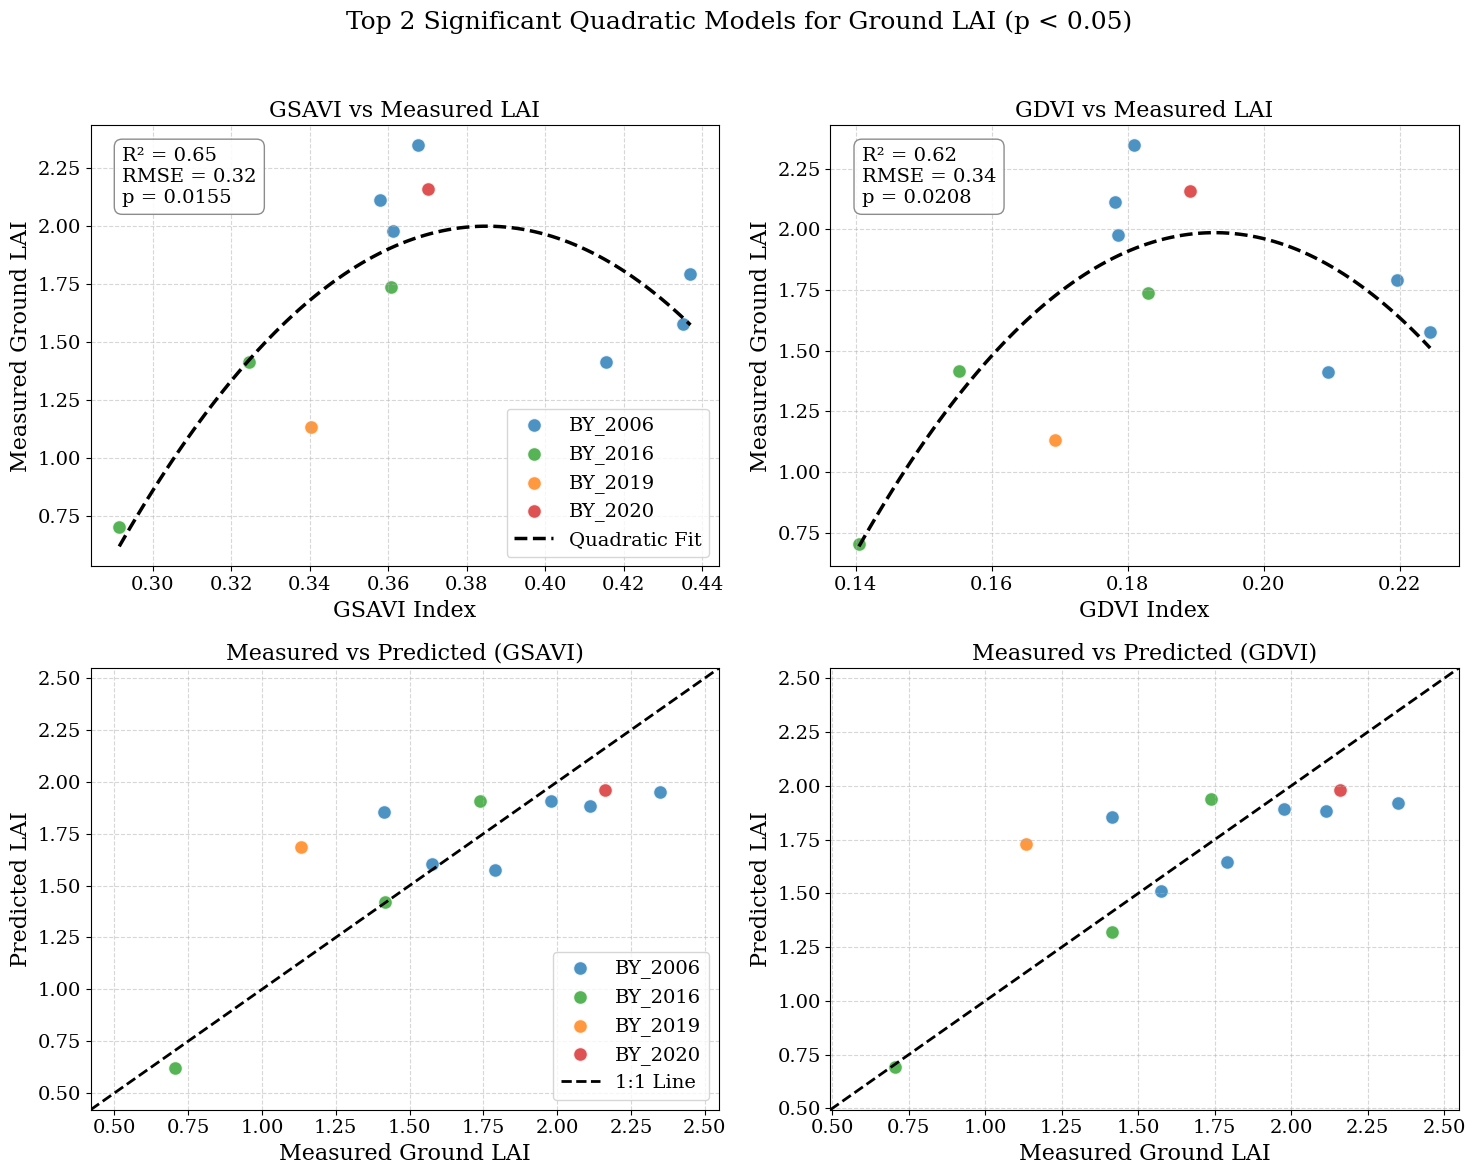

In [36]:
## A11. Plot the Result

import statsmodels.api as sm

# The top 2 metrics that met the p < 0.05 significance level as well as show good loocv performance
top_metrics = ['GSAVI', 'GDVI'] # Concluded from LOOCV
target = 'LAI_mean'
color_mapping = {
    'BY_2006': '#1f77b4',
    'BY_2016': '#2ca02c',
    'BY_2019': '#ff7f0e',
    'BY_2020': '#d62728',
}

# Create a 2x3 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Top 2 Significant Quadratic Models for Ground LAI (p < 0.05)', y=0.98)

for i, metric in enumerate(top_metrics):
    mask = np.isfinite(final_spectra_df[metric]) & np.isfinite(final_spectra_df[target])
    valid_df = final_spectra_df[mask].copy()
    
    x = valid_df[metric].values
    y = valid_df[target].values
    datasets = valid_df['dataset'].values
    
    # Re-fit the Quadratic Model (y = c + b1*x + b2*x^2)
    X_quad = np.column_stack((x, x**2))
    X_quad = sm.add_constant(X_quad)
    mod = sm.OLS(y, X_quad).fit()
    y_pred = mod.predict(X_quad)
    
    # Row 1: Metric vs Measured LAI
    ax1 = axes[0, i]
    
    # Scatter plot grouped by dataset (Burn Year)
    for ds in valid_df['dataset'].unique():
        ds_mask = (datasets == ds)
        ax1.scatter(x[ds_mask], y[ds_mask], color=color_mapping.get(ds, 'black'), 
                    alpha=0.8, edgecolor='w', s=100, label=ds)
        
    # Smooth curve for the fitted quadratic line
    x_line = np.linspace(x.min(), x.max(), 100)
    X_line_quad = np.column_stack((x_line, x_line**2))
    X_line_quad = sm.add_constant(X_line_quad)
    y_line = mod.predict(X_line_quad)
    
    ax1.plot(x_line, y_line, color='black', linewidth=2.5, linestyle='--', label='Quadratic Fit')
    r2 = mod.rsquared
    rmse = np.sqrt(mod.mse_resid)
    p_val = mod.f_pvalue
    stats_text = f"R² = {r2:.2f}\nRMSE = {rmse:.2f}\np = {p_val:.4f}"
    
    ax1.text(0.05, 0.95, stats_text, transform=ax1.transAxes,
            verticalalignment='top', bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.9, edgecolor='gray'))
    
    ax1.set_xlabel(f"{metric} Index")
    ax1.set_ylabel("Measured Ground LAI")
    ax1.set_title(f"{metric} vs Measured LAI")
    ax1.grid(True, linestyle='--', alpha=0.5)
    
    # Row 2: Measured vs Predicted LAI

    ax2 = axes[1, i]
    
    # Scatter plot grouped by dataset
    for ds in valid_df['dataset'].unique():
        ds_mask = (datasets == ds)
        ax2.scatter(y[ds_mask], y_pred[ds_mask], color=color_mapping.get(ds, 'black'), 
                    alpha=0.8, edgecolor='w', s=100, label=ds)
        
    # Plot the 1:1 Line (Perfect Prediction Line)
    min_val = min(y.min(), y_pred.min()) - 0.2
    max_val = max(y.max(), y_pred.max()) + 0.2
    ax2.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', linewidth=2, label='1:1 Line')
    
    # Format axes to be perfectly square/equal for the 1:1 plot
    ax2.set_xlim([min_val, max_val])
    ax2.set_ylim([min_val, max_val])
    ax2.set_xlabel("Measured Ground LAI")
    ax2.set_ylabel("Predicted LAI")
    ax2.set_title(f"Measured vs Predicted ({metric})")
    ax2.grid(True, linestyle='--', alpha=0.5)

    # Add legends only to the first column to keep the plot uncluttered
    if i == 0:
        # Deduplicate legend handles
        handles, labels = ax1.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        ax1.legend(by_label.values(), by_label.keys(), loc='lower right')
        
        handles2, labels2 = ax2.get_legend_handles_labels()
        by_label2 = dict(zip(labels2, handles2))
        ax2.legend(by_label2.values(), by_label2.keys(), loc='lower right')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
## A12. Now use GDVI based quadratic model to predict LAI across the entire rasters

from rasterio.enums import Resampling

metric = 'GDVI'
target = 'LAI_mean'

# Fit the GDVI Quadratic model
mask = np.isfinite(final_spectra_df[metric]) & np.isfinite(final_spectra_df[target])
x = final_spectra_df[metric][mask].values
y = final_spectra_df[target][mask].values

X_quad = np.column_stack((x, x**2))
X_quad = sm.add_constant(X_quad)
mod = sm.OLS(y, X_quad).fit()
c, b1, b2 = mod.params
print(f"Applying Model: LAI = {c:.4f} + {b1:.4f}*(GDVI) + {b2:.4f}*(GDVI^2)\n")

# Process each raster to generate spatial LAI maps
green_idx = 1  # Band 1: 550nm (Green)
nir_idx = 4    # Band 4: 850nm (NIR)

target_resolution = 5.0 # Resample to 5x5m pixels
nodata_value = -9999.0

output_dir = "./uas_modeled_MSI_LAI_Maps_5m"
os.makedirs(output_dir, exist_ok=True)

# Loop through the datasets
for name, path in file_map.items():
    with rasterio.open(path) as src:
        
        # Calculate scaling factor to reach 5m target resolution
        scale_factor_x = src.res[0] / target_resolution
        scale_factor_y = src.res[1] / target_resolution
        
        new_width = int(src.width * scale_factor_x)
        new_height = int(src.height * scale_factor_y)
        
        # Read the bands and block-average them to 5m pixels
        green = src.read(
            green_idx,
            out_shape=(new_height, new_width),
            resampling=Resampling.average
        )
        nir = src.read(
            nir_idx,
            out_shape=(new_height, new_width),
            resampling=Resampling.average
        )
        
        # Calculate the new spatial transform for the 5m raster
        new_transform = src.transform * src.transform.scale(
            (src.width / new_width),
            (src.height / new_height)
        )
        
        # Apply the GDVI-based quadratic model 
        # Create a valid mask to ignore black edges/nodata areas (where Green and NIR are 0)
        valid_mask = (green > 0) & (nir > 0)
        gdvi = np.zeros_like(green, dtype=np.float32)
        lai_pred = np.full_like(green, nodata_value, dtype=np.float32)
        
        # Calculate GDVI only where there is actual drone data
        gdvi[valid_mask] = nir[valid_mask] - green[valid_mask]
        lai_pred[valid_mask] = c + (b1 * gdvi[valid_mask]) + (b2 * (gdvi[valid_mask]**2))
        
        # Clip LAI at 0
        lai_pred[(valid_mask) & (lai_pred < 0)] = 0.0

        # Save the file
        out_meta = src.meta.copy()
        out_meta.update({
            "driver": "GTiff",
            "height": new_height,
            "width": new_width,
            "transform": new_transform,
            "count": 1,
            "dtype": 'float32',
            "nodata": nodata_value
        })
        
        out_path = os.path.join(output_dir, f"{name}_LAI_5m.tif")
        # with rasterio.open(out_path, "w", **out_meta) as dest:
        #     dest.write(lai_pred, 1)
            
    # print(f"Successfully generated 5m LAI map for {name}")

print("\nAll spatial LAI maps successfully saved")

Applying Model: LAI = -15.5842 + 182.2968*(GDVI) + -472.8287*(GDVI^2)

Successfully generated 5m LAI map for BY_2006
Successfully generated 5m LAI map for BY_2016
Successfully generated 5m LAI map for BY_2019
Successfully generated 5m LAI map for BY_2020
Successfully generated 5m LAI map for BY_2017_16

All spatial LAI maps successfully saved


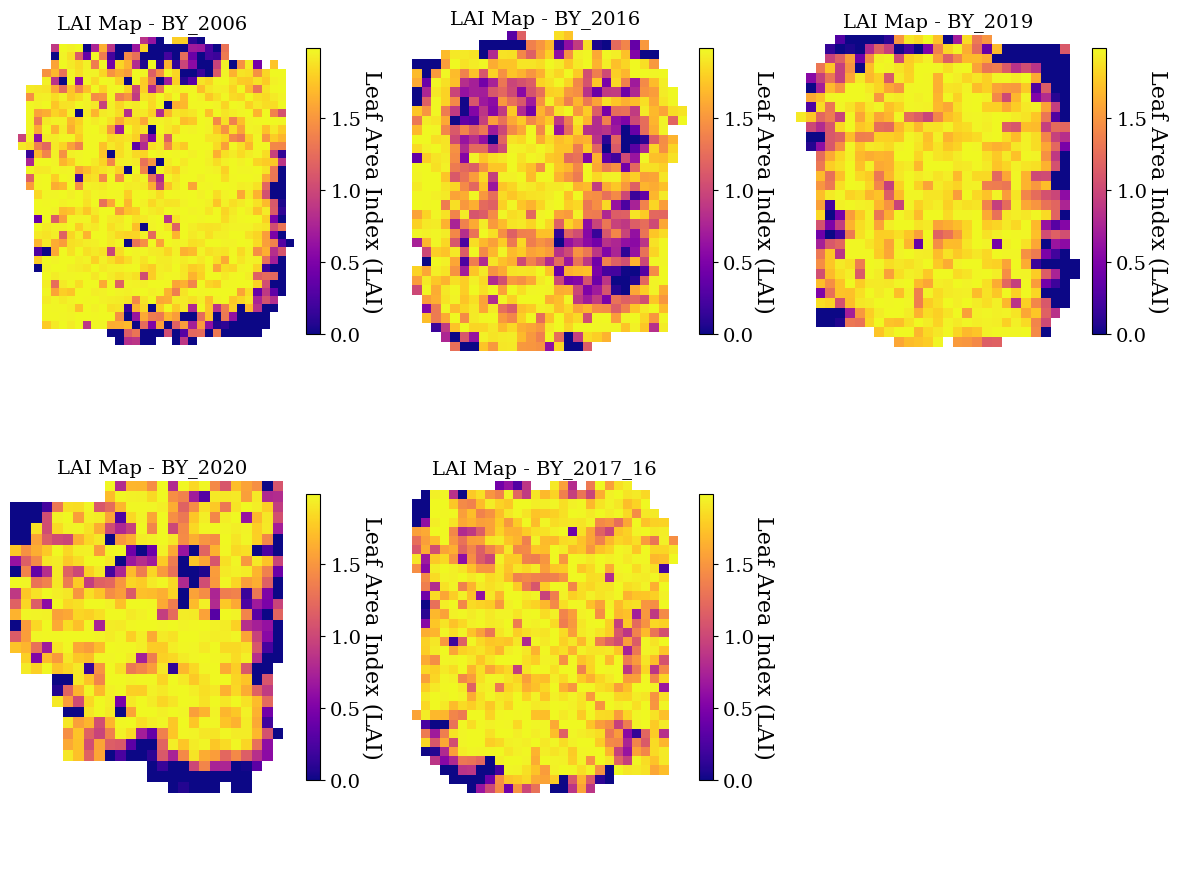

In [38]:
## A13. Visualize the predicted LAI maps

dataset_names = list(file_map.keys())
global_max_lai = 0
lai_data_dict = {}
extents_dict = {}

for name in dataset_names:
    tif_path = os.path.join(output_dir, f"{name}_LAI_5m.tif")
    if os.path.exists(tif_path):
        with rasterio.open(tif_path) as src:
            lai_array = src.read(1)
            
            # Mask out the -9999.0 nodata background
            masked_lai = np.ma.masked_where(lai_array == -9999.0, lai_array)
            
            # Store the data and geographic bounds for plotting
            lai_data_dict[name] = masked_lai
            bounds = src.bounds
            extents_dict[name] = [bounds.left, bounds.right, bounds.bottom, bounds.top]
            
            # Update global max
            current_max = masked_lai.max()
            if current_max > global_max_lai:
                global_max_lai = current_max

cols = 3
rows = int(np.ceil(len(dataset_names) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(12, 5 * rows))

# Flatten axes array for easy iteration
if isinstance(axes, np.ndarray):
    axes_flat = axes.flatten()
else:
    axes_flat = [axes]

# Plot masked arrays
for i, name in enumerate(dataset_names):
    ax = axes_flat[i]
    
    if name in lai_data_dict:
        masked_lai = lai_data_dict[name]
        extent = extents_dict[name]
        im = ax.imshow(masked_lai, cmap='plasma', vmin=0, vmax=global_max_lai, extent=extent)
        ax.set_title(f"LAI Map - {name}", fontsize=14)
        ax.set_xlabel("Easting")
        ax.set_ylabel("Northing")
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label('Leaf Area Index (LAI)', rotation=270, labelpad=15)
        ax.ticklabel_format(useOffset=False, style='plain')
        ax.set_axis_off()
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
for j in range(len(dataset_names), len(axes_flat)):
    axes_flat[j].axis('off')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [39]:
"""

B. AVIRIS-NG data for LAI modeling. 
   Now we are using drone-based rasters to harmonize the full AVIRIS-NG data not just few broadbands and try comparing the performance again:
   1. Using RF-based Harmonization and see performance
      - For raw AVIRIS-NG
      - For RF-harmonized AVIRIS-NG

"""

'\n\nB. AVIRIS-NG data for LAI modeling. \n   Now we are using drone-based rasters to harmonize the full AVIRIS-NG data not just few broadbands and try comparing the performance again:\n   1. Using RF-based Harmonization and see performance\n      - For raw AVIRIS-NG\n      - For RF-harmonized AVIRIS-NG\n\n'

In [40]:
## AVIRIS-NG based LAI modeling

## B1. Load the AVIRIS-NG rasters

raster_files = [
    "./AVIRIS_NG_data/ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
    "./AVIRIS_NG_data/ang20231109t062226_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
    "./AVIRIS_NG_data/ang20231109t062226_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
    "./AVIRIS_NG_data/ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc"
]


## Load LAI ground measurements shapefile
gdf = gpd.read_file(LAI_measurement_shapefile)

In [41]:
## B2. Extract AVIRIS-NG spectra at the LAI plot locations

from rasterio.mask import mask

# Create a dictionary to hold candidate spectra for each plot
candidates = {pid: [] for pid in gdf['plot_id'].unique()}
wavelengths = None

print(f"Starting Robust Extraction for {len(gdf)} plots...")

# Main loop through raster files
for nc_file in raster_files:
    if os.path.exists(nc_file):
        actual_path = nc_file
    elif os.path.exists(os.path.basename(nc_file)):
        actual_path = os.path.basename(nc_file)
    else: continue

    netcdf_path = f"NETCDF:{actual_path}:/reflectance/reflectance"

    try:
        with rasterio.open(netcdf_path) as src:
            # 1. Capture wavelengths
            if wavelengths is None:
                with Dataset(actual_path, mode="r") as ds:
                    wavelengths = ds.groups["reflectance"].variables["wavelength"][:]

            # 2. Project plots to match raster CRS
            gdf_local = gdf.to_crs(src.crs)

            # 3. Iterate plots
            for idx, row in gdf_local.iterrows():
                geom = row.geometry
                bounds = src.bounds
                
                # Check if plot is within image extents
                if not box(bounds.left, bounds.bottom, bounds.right, bounds.top).intersects(geom):
                    continue

                try:
                    # ATTEMPT 1: Exact polygon mask
                    # all_touched=True ensures we grab pixels on the edges
                    out_image, _ = mask(src, [geom], crop=True, all_touched=True, nodata=-9999)
                    data = out_image.reshape(out_image.shape[0], -1)
                    
                    # Filter valid pixels (using band 100 as a check)
                    valid_mask = (data[100, :] > -50) 
                    valid_pixels = data[:, valid_mask]
                    
                    # ATTEMPT 2: Centroid fallback if no valid pixels from polygon
                    # If the polygon mask failed (0 pixels), grab the center pixel ONLY
                    if valid_pixels.shape[1] == 0:
                        cx, cy = geom.centroid.x, geom.centroid.y
                        r, c = src.index(cx, cy)
                        # Ensure centroid is inside the image grid
                        if 0 <= r < src.height and 0 <= c < src.width:
                            window = rasterio.windows.Window(c, r, 1, 1)
                            centroid_data = src.read(window=window).reshape(src.count, -1)
                            if np.all(centroid_data[100, :] > -50):
                                valid_pixels = centroid_data

                    # Save valid spectra if we have any
                    if valid_pixels.shape[1] > 0:
                        mean_spectrum = np.mean(valid_pixels, axis=1)
                        img_cx, img_cy = (bounds.left + bounds.right)/2, (bounds.top + bounds.bottom)/2
                        dist = np.sqrt((geom.centroid.x - img_cx)**2 + (geom.centroid.y - img_cy)**2)
                        
                        candidates[row['plot_id']].append({
                            'spectrum': mean_spectrum,
                            'dist': dist,
                            'file': os.path.basename(actual_path),
                            'pixels': valid_pixels.shape[1]
                        })
                        
                except Exception:
                    continue

    except Exception as e:
        print(f"  [ERROR] {os.path.basename(actual_path)}: {e}")

# Finalize records by picking the best spectrum for each plot
final_records = []
for pid, data_list in candidates.items():
    if not data_list:
        print(f"  [FAILED] Plot {pid}: No data found.")
        continue
    
    data_list.sort(key=lambda x: x['dist']) # Pick the nadir-most flightline
    best = data_list[0]
    
    rec = {
        'plot_id': pid, 'source_file': best['file'], 
        'dist_to_center': round(best['dist'], 1), 'pixels_used': best['pixels']
    }
    for i, val in enumerate(best['spectrum']):
        rec[f'band_{i}'] = val
    final_records.append(rec)

df_spectra = pd.DataFrame(final_records)
print(f"Extraction Complete: {len(df_spectra)} / {len(gdf)} plots.")

Starting Robust Extraction for 20 plots...
Extraction Complete: 20 / 20 plots.


Plotting all spectral signatures...


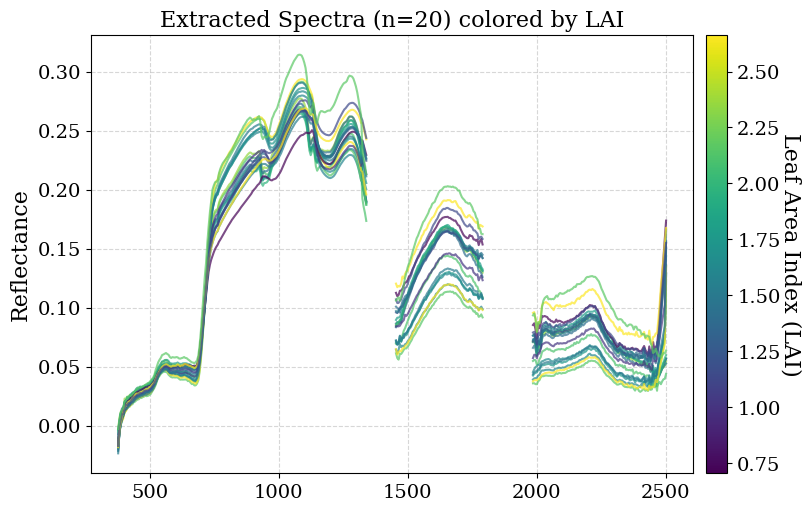

In [42]:
## B3. Visualize the extracted spectra at the ground plot locations.

# Ensure we have the LAI values attached to the spectra
plot_data = df_spectra.merge(gdf[['plot_id', 'LAI_mean']], on='plot_id', how='left')

# Extract just the band columns for plotting
band_cols = sorted([c for c in plot_data.columns if c.startswith('band_')], 
                   key=lambda x: int(x.split('_')[1]))

X_plot = plot_data[band_cols].values
lai_values = plot_data['LAI_mean'].values

# Plotting setup
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
norm = mcolors.Normalize(vmin=np.nanmin(lai_values), vmax=np.nanmax(lai_values)) # Color map based on LAI values
cmap = cm.viridis
print(f"Plotting all spectral signatures...")

for i in range(len(X_plot)):
    # Get spectrum and LAI
    spectrum = X_plot[i]
    lai = lai_values[i]
    
    # Mask out "bad" water absorption bands for cleaner plotting
    # Common AVIRIS-NG bad bands: ~1350-1420nm and ~1800-1950nm
    spectrum_masked = spectrum.copy()
    
    # Identify indices of water bands (approximate)
    bad_indices = np.where(
        ((wavelengths > 1340) & (wavelengths < 1450)) | 
        ((wavelengths > 1790) & (wavelengths < 1980))
    )[0]
    spectrum_masked[bad_indices] = np.nan
    
    # Plot line
    color = cmap(norm(lai))
    ax.plot(wavelengths, spectrum_masked, color=color, alpha=0.7, linewidth=1.5)
    target_wavelengths = [2005.0, 2320.6]
    for wl in target_wavelengths:
        idx = (np.abs(wavelengths - wl)).argmin()

# Add colorbar for LAI
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Leaf Area Index (LAI)', rotation=270, labelpad=15)
ax.set_title(f"Extracted Spectra (n={len(X_plot)}) colored by LAI")
ax.set_ylabel("Reflectance")
ax.set_label("Wavelength (nm)")
ax.grid(which = 'both', linestyle='--', alpha=0.5)
plt.show()

In [43]:
# ## Print the dataframe with 20 ground plots.

plot_data

,plot_id,source_file,dist_to_center,pixels_used,band_0,band_1,band_2,band_3,band_4,band_5,...,band_416,band_417,band_418,band_419,band_420,band_421,band_422,band_423,band_424,LAI_mean
0,GBS0619,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2069.8,2,-0.012839,-0.000597,0.005537,0.009045,0.011444,0.016510,...,0.035863,0.033181,0.035569,0.036930,0.035091,0.037592,0.039288,0.039655,0.043875,2.112576
1,GBS0622,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2033.0,1,-0.003114,0.006765,0.011716,0.010504,0.014015,0.022895,...,0.046204,0.038042,0.046299,0.044567,0.045119,0.048770,0.049470,0.050644,0.054497,2.348314
2,GBS0625,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2078.1,2,-0.010381,-0.000451,0.009333,0.011443,0.013812,0.019793,...,0.046227,0.043486,0.043235,0.043492,0.046015,0.048172,0.049881,0.051346,0.052706,1.575255
3,GBS0626,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2004.2,4,-0.003502,0.003047,0.009716,0.012301,0.015389,0.020258,...,0.048921,0.044205,0.044812,0.047745,0.049028,0.050746,0.053250,0.054480,0.056589,1.790895
4,GBS0627,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2000.4,4,-0.006965,0.004148,0.010290,0.014685,0.014490,0.018344,...,0.042140,0.041345,0.040841,0.042606,0.046406,0.048729,0.050940,0.054166,0.057023,1.413221
5,GBS06P,ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT...,2099.4,2,-0.005079,-0.000273,0.010613,0.010944,0.014199,0.019529,...,0.038917,0.041805,0.041572,0.043249,0.046657,0.048604,0.053699,0.057122,0.059680,1.977499
6,GBS161,ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT...,956.4,4,-0.019429,-0.003855,0.000484,0.004669,0.008724,0.011589,...,0.033406,0.037939,0.050893,0.055695,0.061688,0.066478,0.071469,0.076401,0.128763,1.603689
7,GBS162,ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT...,1105.2,2,-0.017971,-0.004858,0.002037,0.005088,0.007893,0.011398,...,0.035306,0.029535,0.040353,0.046807,0.053974,0.060246,0.066512,0.072966,0.123309,2.146058
8,GBS164,ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT...,955.4,4,-0.016836,-0.006069,0.003055,0.005517,0.008959,0.012046,...,0.036427,0.040728,0.051072,0.054738,0.061019,0.065443,0.069919,0.074534,0.135696,1.737210
9,GBS168,ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT...,1072.7,2,-0.018575,-0.005444,0.001595,0.004601,0.009180,0.011785,...,0.047335,0.041761,0.051851,0.056210,0.062712,0.067510,0.072588,0.077806,0.129008,1.622965


--- Phase 1: Continuous 5x5m Fishnet Extraction ---
Processing BY_2006...
  -> Valid: 973 | Rejected: 357
Processing BY_2016...
  -> Valid: 758 | Rejected: 262
Processing BY_2019...
  -> Valid: 680 | Rejected: 248
Processing BY_2020...
  -> Valid: 529 | Rejected: 254
Processing BY_2017_16...
  -> Valid: 746 | Rejected: 308

--- Phase 2: Extracting AVIRIS Spectra for 3686 plots ---
Extraction Complete! 3686 perfectly matched points.

--- Phase 3: ML Cross-Sensor Band Translation ---
Training Random Forest to harmonize AVIRIS-NG spectra to drone Green...
Training Random Forest to harmonize AVIRIS-NG spectra to drone Red...
Training Random Forest to harmonize AVIRIS-NG spectra to drone RedEdge...
Training Random Forest to harmonize AVIRIS-NG spectra to drone NIR...


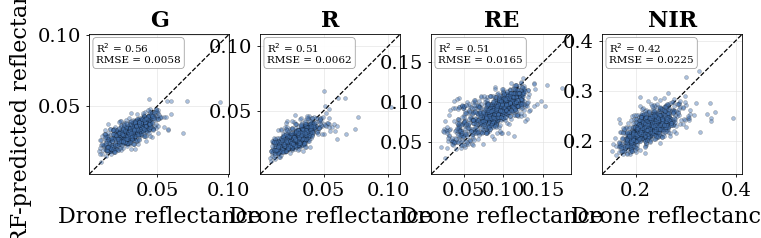


--- Random Forest Band Harmonization Performance (Test Set) ---
Green   | R² = 0.56 | RMSE = 0.0058
Red     | R² = 0.51 | RMSE = 0.0062
RedEdge | R² = 0.51 | RMSE = 0.0165
NIR     | R² = 0.42 | RMSE = 0.0225

--------------------------------------------------------------------------------
Phase 4: UAS-Guided Spectral Harmonization via Interpolated Gain Curve
--------------------------------------------------------------------------------
harmonized spectra saved for 20 plots.

Generating representative drone-guided gain curve plot...


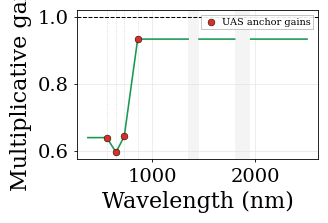

Generating representative before/after spectral comparison plot...


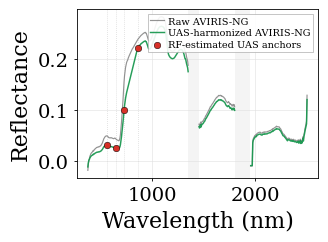


------------------------------------------------------------------------------------------------------------------------
                                Top Performing Unique Indices (Sorted by harmonized R2)                                 
------------------------------------------------------------------------------------------------------------------------
              Index       Model  raw_R2  harmon_R2  R2_%_Imp  raw_RMSE  harmon_RMSE  RMSE_%_Imp
                CAI   Quadratic   0.528      0.538       1.9     0.353        0.349         1.1
Custom_SWIR_Primary   Quadratic   0.525      0.525       0.0     0.354        0.354         0.0
Custom_SWIR1_Bridge   Quadratic   0.409      0.409      -0.0     0.395        0.395        -0.0
 Custom_NIR_Plateau   Quadratic   0.387      0.387      -0.0     0.402        0.402        -0.0
   Custom_VIS_Green   Quadratic   0.366      0.366      -0.0     0.409        0.409        -0.0
               NDLI   Quadratic   0.288      0.322      11.8

In [44]:
## B4. Cross-sensor Harmonization Chain for Single Metric Analysis: Refer to our paper for details..

# -------------------------------------------------------------------------
# PHASE 1 & 2: Virtual plot extraction & AVIRIS matching
# -------------------------------------------------------------------------

file_map = {
    "BY_2006": "./Drone_msi_data/burn2006_lr_band_stack.tif",
    "BY_2016": "./Drone_msi_data/burn2016_lr_band_stack.tif",
    "BY_2019": "./Drone_msi_data/burn2019_lr_band_stack.tif",
    "BY_2020": "./Drone_msi_data/burn2020_lr_band_stack.tif",
    "BY_2017_16": "./Drone_msi_data/burn2017_2016_lr_band_stack.tif"
}

grid_size_m = 5.0
virtual_plots = []
drone_crs = None 

# Plot formatting
def format_1to1_axis(ax, min_val, max_val):
    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="black",
        linestyle="--",
        linewidth=0.9,
        zorder=1
    )
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, color="0.88", linewidth=0.4)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=2.5, width=0.6)

    for spine in ax.spines.values():
        spine.set_linewidth(0.6)


def add_stats_box(ax, text):
    ax.text(
        0.05,
        0.95,
        text,
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=7.5,
        linespacing=1.20,
        bbox={
            "boxstyle": "round,pad=0.32",
            "facecolor": "white",
            "edgecolor": "0.55",
            "linewidth": 0.5,
            "alpha": 0.95,
        }
    )

print("--- Phase 1: Continuous 5x5m Fishnet Extraction ---")

for site, path in file_map.items():
    print(f"Processing {site}...")
    with rasterio.open(path) as src:
        if drone_crs is None: drone_crs = src.crs
        bounds = src.bounds
        valid_grids, rejected_nodata = 0, 0
        
        x_coords = np.arange(bounds.left, bounds.right, grid_size_m)
        y_coords = np.arange(bounds.bottom, bounds.top, grid_size_m)
        
        for x, y in itertools.product(x_coords[:-1], y_coords[:-1]):
            left, bottom = x, y
            right, top = x + grid_size_m, y + grid_size_m
            
            try:
                row_start, col_start = src.index(left, top)
                row_stop, col_stop = src.index(right, bottom)
                
                win = Window.from_slices((row_start, row_stop), (col_start, col_stop))
                data = src.read(window=win)
                
                if data.size > 0 and np.all(data > 0) and not np.isnan(data).any():
                    virtual_plots.append({
                        'plot_id': f"{site}_Grid_{valid_grids+1}",
                        'geometry': Point(left + (grid_size_m / 2), bottom + (grid_size_m / 2)),
                        'Drone_G': np.mean(data[0]),
                        'Drone_R': np.mean(data[1]),
                        'Drone_RE': np.mean(data[2]),
                        'Drone_NIR': np.mean(data[3]),
                        'site': site
                    })
                    valid_grids += 1
                else:
                    rejected_nodata += 1
            except Exception:
                pass 
        print(f"  -> Valid: {valid_grids} | Rejected: {rejected_nodata}")

if not virtual_plots:
    raise ValueError("CRITICAL ERROR: No grids were extracted.")

gdf_virtual = gpd.GeoDataFrame(virtual_plots, crs=drone_crs, geometry='geometry')

print(f"\n--- Phase 2: Extracting AVIRIS Spectra for {len(gdf_virtual)} plots ---")
candidates = {pid: [] for pid in gdf_virtual['plot_id'].unique()}
wavelengths = None

for nc_file in raster_files:
    actual_path = nc_file if os.path.exists(nc_file) else os.path.basename(nc_file)
    if not os.path.exists(actual_path): continue

    try:
        with rasterio.open(f"NETCDF:{actual_path}:/reflectance/reflectance") as src:
            if wavelengths is None:
                with Dataset(actual_path, mode="r") as ds:
                    wavelengths = ds.groups["reflectance"].variables["wavelength"][:]

            gdf_local = gdf_virtual.to_crs(src.crs)
            flightline_box = box(src.bounds.left, src.bounds.bottom, src.bounds.right, src.bounds.top)

            for idx, row in gdf_local.iterrows():
                geom = row.geometry
                if not flightline_box.contains(geom): continue

                try:
                    r, c = src.index(geom.x, geom.y)
                    if 0 <= r < src.height and 0 <= c < src.width:
                        data_2d = src.read(window=Window(c, r, 1, 1)).reshape(src.count, -1)
                        if data_2d[100, 0] > -50: 
                            dist = np.sqrt((geom.x - (src.bounds.left + src.bounds.right)/2)**2 + 
                                           (geom.y - (src.bounds.top + src.bounds.bottom)/2)**2)
                            candidates[row['plot_id']].append({
                                'spectrum': data_2d[:, 0], 'dist': dist, 'file': os.path.basename(actual_path)
                            })
                except Exception:
                    continue
    except Exception as e:
        print(f"  [ERROR] {os.path.basename(actual_path)}: {e}")

final_aviris_records = []
for pid, data_list in candidates.items():
    if not data_list: continue 
    best = sorted(data_list, key=lambda x: x['dist'])[0]
    rec = {'plot_id': pid}
    rec.update({f'band_{i}': val for i, val in enumerate(best['spectrum'])})
    final_aviris_records.append(rec)

big_dataset = pd.merge(gdf_virtual.drop(columns='geometry'), pd.DataFrame(final_aviris_records), on='plot_id', how='inner')
print(f"Extraction Complete! {len(big_dataset)} perfectly matched points.")


# -------------------------------------------------------------------------
# PHASE 3: RF-based cross-sensor band harmonization (AVIRIS-NG to Drone)
# -------------------------------------------------------------------------

print("\n--- Phase 3: ML Cross-Sensor Band Translation ---")

drone_targets = {
    "Green": "Drone_G",
    "Red": "Drone_R",
    "RedEdge": "Drone_RE",
    "NIR": "Drone_NIR"
}

aviris_band_cols = [col for col in big_dataset.columns if col.startswith("band_")]

clean_data = big_dataset[
    (big_dataset[["Drone_G", "Drone_R", "Drone_RE", "Drone_NIR"]] > 0).all(axis=1)
].copy()

X_full = clean_data[aviris_band_cols]

fig, axes = plt.subplots(1, 4, figsize=(7.1, 2.15))

rf_models = {}
rf_metrics = {}

band_label_map = {
    "Green": "G",
    "Red": "R",
    "RedEdge": "RE",
    "NIR": "NIR",
}

for ax, (band_name, drone_col) in zip(axes, drone_targets.items()):
    print(f"Training Random Forest to harmonize AVIRIS-NG spectra to drone {band_name}...")

    y = clean_data[drone_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X_full,
        y,
        test_size=0.30,
        random_state=42
    )

    rf = RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)
    y_pred_test = rf.predict(X_test)

    test_r2 = r2_score(y_test, y_pred_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

    rf_models[band_name] = rf
    rf_metrics[band_name] = {
        "R2": test_r2,
        "RMSE": test_rmse
    }

    min_val = min(y_test.min(), y_pred_test.min())
    max_val = max(y_test.max(), y_pred_test.max())
    pad = 0.08 * (max_val - min_val)
    axis_min = min_val - pad
    axis_max = max_val + pad

    ax.scatter(
        y_test,
        y_pred_test,
        color="#4575b4",
        edgecolor="black",
        linewidth=0.25,
        s=8,
        alpha=0.45,
        zorder=2
    )

    format_1to1_axis(ax, axis_min, axis_max)

    stats_text = (
        f"R$^2$ = {test_r2:.2f}\n"
        f"RMSE = {test_rmse:.4f}"
    )
    add_stats_box(ax, stats_text)

    ax.set_title(
        band_label_map.get(band_name, band_name),
        fontweight="bold",
        pad=5
    )

    ax.set_xlabel("Drone reflectance")

axes[0].set_ylabel("RF-predicted reflectance")

fig.subplots_adjust(
    left=0.075,
    right=0.995,
    bottom=0.22,
    top=0.88,
    wspace=0.22
)

plt.show()

print("\n--- Random Forest Band Harmonization Performance (Test Set) ---")
for band, metrics in rf_metrics.items():
    print(f"{band:7s} | R² = {metrics['R2']:.2f} | RMSE = {metrics['RMSE']:.4f}")


# -------------------------------------------------------------------------
# PHASE 4: UAS-Guided Spectral Harmonization via Interpolated Gain Curve
# -------------------------------------------------------------------------
print("\n" + "-"*80)
print("Phase 4: UAS-Guided Spectral Harmonization via Interpolated Gain Curve")
print("-"*80)

clean_wls = wavelengths.filled(np.nan) if np.ma.isMaskedArray(wavelengths) else np.array(wavelengths)
X_20 = plot_data[aviris_band_cols]

for band, col in zip(['Green', 'Red', 'RedEdge', 'NIR'], ['Sim_Drone_G', 'Sim_Drone_R', 'Sim_Drone_RE', 'Sim_Drone_NIR']):
    plot_data[col] = rf_models[band].predict(X_20)

drone_bands = {
    'Green': {'center': 560, 'tol': 16, 'col': 'Sim_Drone_G'},
    'Red': {'center': 650, 'tol': 16, 'col': 'Sim_Drone_R'},
    'RedEdge': {'center': 730, 'tol': 16, 'col': 'Sim_Drone_RE'},
    'NIR': {'center': 860, 'tol': 26, 'col': 'Sim_Drone_NIR'}
}
anchor_wls = [v['center'] for v in drone_bands.values()]

harmonized_records, original_spectra, harmonized_spectra = [], [], []
plot_ids = plot_data['plot_id'].values

for idx, row in plot_data.iterrows():
    orig_spectrum = row[aviris_band_cols].values.astype(float)
    original_spectra.append(orig_spectrum)
    
    scaling_factors = []
    for specs in drone_bands.values():
        band_mask = (clean_wls >= specs['center'] - specs['tol']) & (clean_wls <= specs['center'] + specs['tol'])
        aviris_sim = np.mean(orig_spectrum[band_mask])
        scaling_factors.append(row[specs['col']] / (aviris_sim + 1e-6))
        
    gain_interpolator = interp1d(anchor_wls, scaling_factors, kind='linear', fill_value=(scaling_factors[0], scaling_factors[-1]), bounds_error=False)
    harmon_spectrum = orig_spectrum * gain_interpolator(clean_wls)
    harmonized_spectra.append(harmon_spectrum)
    
    rec = {'plot_id': row['plot_id'], 'LAI_mean': row['LAI_mean']}
    rec.update({f'band_{i}': val for i, val in enumerate(harmon_spectrum)})
    harmonized_records.append(rec)

harmonized_aviris_df = pd.DataFrame(harmonized_records)
print(f"harmonized spectra saved for {len(harmonized_aviris_df)} plots.\n")

# -------------------------------------------------------------------------
# VISUALIZATION: Representative drone-guided gain curve
# -------------------------------------------------------------------------

print("Generating representative drone-guided gain curve plot...")

# Same representative plot as spectra comparison: median LAI sample
rep_idx = int(np.argsort(plot_data["LAI_mean"].values)[len(plot_data) // 2])

rep_row = plot_data.iloc[rep_idx]
rep_orig_spectrum = rep_row[aviris_band_cols].values.astype(float)

rep_scaling_factors = []

for specs in drone_bands.values():
    band_mask = (
        (clean_wls >= specs["center"] - specs["tol"])
        & (clean_wls <= specs["center"] + specs["tol"])
    )

    aviris_sim = np.nanmean(rep_orig_spectrum[band_mask])
    rep_scaling_factors.append(rep_row[specs["col"]] / (aviris_sim + 1e-6))

rep_scaling_factors = np.asarray(rep_scaling_factors, dtype=float)

gain_interpolator = interp1d(
    anchor_wls,
    rep_scaling_factors,
    kind="linear",
    fill_value=(rep_scaling_factors[0], rep_scaling_factors[-1]),
    bounds_error=False
)

rep_gain_curve = gain_interpolator(clean_wls)

water_bands = (
    ((clean_wls > 1350) & (clean_wls < 1450))
    | ((clean_wls > 1800) & (clean_wls < 1950))
)

rep_gain_curve_plot = rep_gain_curve.copy()
rep_gain_curve_plot[water_bands] = np.nan

fig, ax = plt.subplots(figsize=(3.5, 2.45))

for start, end in [(1350, 1450), (1800, 1950)]:
    ax.axvspan(
        start,
        end,
        color="0.92",
        linewidth=0,
        alpha=0.55,
        zorder=0
    )

for wl in anchor_wls:
    ax.axvline(
        wl,
        color="0.72",
        linestyle=":",
        linewidth=0.55,
        alpha=0.65,
        zorder=1
    )

ax.plot(
    clean_wls,
    rep_gain_curve_plot,
    color="#1a9850",
    linewidth=1.15,
    zorder=3
)

ax.scatter(
    anchor_wls,
    rep_scaling_factors,
    color="#d73027",
    edgecolor="black",
    linewidth=0.35,
    marker="o",
    s=24,
    zorder=4,
    label="UAS anchor gains"
)

ax.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=0.75,
    zorder=2
)

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Multiplicative gain")

ax.grid(True, color="0.88", linewidth=0.4)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=2.5, width=0.6)

for spine in ax.spines.values():
    spine.set_linewidth(0.6)

leg = ax.legend(
    loc="upper right",
    frameon=True,
    fancybox=False,
    edgecolor="0.65",
    facecolor="white",
    framealpha=0.90,
    fontsize=7,
    borderpad=0.28,
    handlelength=1.4,
    handletextpad=0.40,
    labelspacing=0.30
)
leg.get_frame().set_linewidth(0.5)

fig.tight_layout()
plt.show()


# -------------------------------------------------------------------------
# VISUALIZATION: Representative before/after spectra comparison
# -------------------------------------------------------------------------

print("Generating representative before/after spectral comparison plot...")

# Choose representative plot as the median LAI sample
rep_idx = int(np.argsort(plot_data["LAI_mean"].values)[len(plot_data) // 2])

rep_pid = plot_ids[rep_idx]
rep_lai = plot_data.iloc[rep_idx]["LAI_mean"]

plot_orig = np.copy(original_spectra[rep_idx])
plot_harmon = np.copy(harmonized_spectra[rep_idx])

water_bands = (
    ((clean_wls > 1350) & (clean_wls < 1450))
    | ((clean_wls > 1800) & (clean_wls < 1950))
)

plot_orig[water_bands] = np.nan
plot_harmon[water_bands] = np.nan

drone_anchor_values = [
    plot_data.iloc[rep_idx]["Sim_Drone_G"],
    plot_data.iloc[rep_idx]["Sim_Drone_R"],
    plot_data.iloc[rep_idx]["Sim_Drone_RE"],
    plot_data.iloc[rep_idx]["Sim_Drone_NIR"],
]

fig, ax = plt.subplots(figsize=(3.5, 2.65))

# Atmospheric water absorption regions
for start, end in [(1350, 1450), (1800, 1950)]:
    ax.axvspan(
        start,
        end,
        color="0.92",
        linewidth=0,
        alpha=0.55,
        zorder=0
    )

# UAS anchor wavelength guides
for wl in anchor_wls:
    ax.axvline(
        wl,
        color="0.72",
        linestyle=":",
        linewidth=0.55,
        alpha=0.60,
        zorder=1
    )

ax.plot(
    clean_wls,
    plot_orig,
    color="0.50",
    linewidth=0.85,
    alpha=0.85,
    label="Raw AVIRIS-NG",
    zorder=3
)

ax.plot(
    clean_wls,
    plot_harmon,
    color="#1a9850",
    linewidth=1.05,
    alpha=0.95,
    label="UAS-harmonized AVIRIS-NG",
    zorder=4
)

ax.scatter(
    anchor_wls,
    drone_anchor_values,
    color="#d73027",
    edgecolor="black",
    linewidth=0.35,
    marker="o",
    s=22,
    zorder=5,
    label="RF-estimated UAS anchors"
)

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectance")

ax.grid(True, color="0.88", linewidth=0.4)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=2.5, width=0.6)

for spine in ax.spines.values():
    spine.set_linewidth(0.6)

leg = ax.legend(
    loc="upper right",
    frameon=True,
    fancybox=False,
    edgecolor="0.65",
    facecolor="white",
    framealpha=0.90,
    fontsize=7,
    borderpad=0.28,
    handlelength=1.4,
    handletextpad=0.40,
    labelspacing=0.30
)
leg.get_frame().set_linewidth(0.5)

fig.tight_layout()
plt.show()

# ---------------------------------------------------------------------------------
# PHASE 5: Performance comparison of raw vs. harmonized AVIRIS-NG for LAI prediction
# ---------------------------------------------------------------------------------

def compute_aicc(n, rss, k):
    return (n * np.log(max(rss, 1e-10) / n) + 2 * k) + (2 * k * (k + 1)) / (n - k - 1)

def power_func(x, a, b): return a * np.power(x, b)

def calculate_all_indices(X_mat, wave_arr):
    # Pre-extract required bands 
    w_targets = [
        480, 527.4, 531, 547.4, 550, 570, 670, 681, 709, 720, 754, 800, 850, 860, 
        1240, 1243.6, 1288.7, 1650, 1680, 1729.5, 1749.5, 1750, 2005, 2100, 
        2210, 2260, 2320.5
    ]
    b = {w: X_mat[:, np.argmin(np.abs(wave_arr - w))] for w in w_targets}
    eps = 1e-6

    # Calculate base NDVI for use in composite indices like NIRv
    ndvi = (b[850] - b[670]) / (b[850] + b[670] + eps)

    return {
        # NDVI: Normalized Difference Vegetation Index for general greenness 
        "NDVI": ndvi,
        # SR: Simple Ratio, the basic NIR/Red slope 
        "SR": b[850] / (b[670] + eps),
        # GNDVI: Green NDVI, sensitive to chlorophyll concentration 
        "GNDVI": (b[850] - b[550]) / (b[850] + b[550] + eps),
        # GRVI: Green-Red Vegetation Index 
        "GRVI": (b[550] - b[670]) / (b[550] + b[670] + eps),
        # GDVI: Green Difference Vegetation Index for biomass estimation (Standard Difference)
        "GDVI": b[850] - b[550],
        # SAVI: Soil-Adjusted Vegetation Index with L=0.5
        "SAVI": 1.5 * (b[850] - b[670]) / (b[850] + b[670] + 0.5 + eps),
        # GSAVI: Green version of SAVI to reduce soil background in nitrogen tests 
        "GSAVI": 1.5 * (b[850] - b[550]) / (b[850] + b[550] + 0.5 + eps),
        # OSAVI: Optimized Soil-Adjusted Vegetation Index for sparse canopy 
        "OSAVI": 1.16 * (b[850] - b[670]) / (b[850] + b[670] + 0.16 + eps),
        # MSAVI2: Modified Soil-Adjusted Vegetation Index 2, iterative version 
        "MSAVI2": 0.5 * (2 * b[850] + 1 - np.sqrt(np.maximum((2 * b[850] + 1)**2 - 8 * (b[850] - b[670]), 0))),
        # NDRE: Normalized Difference Red Edge Index for mid-to-late season vigor
        "NDRE": (b[850] - b[720]) / (b[850] + b[720] + eps),
        # SR_RE: Red Edge Simple Ratio, sensitive to high LAI chlorophyll 
        "SR_RE": b[850] / (b[720] + eps),
        # CI_RE: Chlorophyll Index Red Edge for leaf chlorophyll content 
        "CI_RE": (b[850] / (b[720] + eps)) - 1,
        # MTCI: MERIS Terrestrial Chlorophyll Index for red edge position 
        "MTCI": (b[754] - b[709]) / (b[709] - b[681] + eps),
        # MSR: Modified Simple Ratio to linearize the relationship with LAI 
        "MSR": (b[850] / (b[670] + eps) - 1) / (np.sqrt(np.maximum(b[850] / (b[670] + eps), 0)) + 1),
        # EVI2: Enhanced Vegetation Index 2 without the blue band
        "EVI2": 2.5 * (b[850] - b[670]) / (b[850] + 2.4 * b[670] + 1 + eps),
        # NDWI: Normalized Difference Water Index for leaf liquid water
        "NDWI": (b[860] - b[1240]) / (b[860] + b[1240] + eps),
        # CAI: Cellulose Absorption Index for crop residue and dry matter
        "CAI": 0.5 * (b[2005] + b[2210]) - b[2100],
        # NDLI: Normalized Difference Lignin Index using absorbance logic
        "NDLI": (np.log(1/(b[1750]+eps)) - np.log(1/(b[1680]+eps))) / (np.log(1/(b[1750]+eps)) + np.log(1/(b[1680]+eps)) + eps), 
        # Custom_SWIR_Primary: optimized SWIR normalized-difference index from band-ratio search
        "Custom_SWIR_Primary": (b[2320.5] - b[2005]) / (b[2320.5] + b[2005] + eps),
        # Custom_NIR_Plateau: optimized NIR plateau normalized-difference index from band-ratio search
        "Custom_NIR_Plateau": (b[1288.7] - b[1243.6]) / (b[1288.7] + b[1243.6] + eps),
        # Custom_VIS_Green: optimized visible green normalized-difference index from band-ratio search
        "Custom_VIS_Green": (b[547.4] - b[527.4]) / (b[547.4] + b[527.4] + eps),
        # Custom_SWIR1_Bridge: optimized SWIR-1 normalized-difference index from band-ratio search
        "Custom_SWIR1_Bridge": (b[1749.5] - b[1729.5]) / (b[1749.5] + b[1729.5] + eps),
        # NIRv: Near-Infrared Reflectance of Vegetation, a structural proxy for GPP
        "NIRv": ndvi * b[850],
        # SATVI: Soil Adjusted Total Vegetation Index for senescent/green biomass
        "SATVI": (1.5 * (b[1650] - b[670]) / (b[1650] + b[670] + 0.5 + eps)) - (b[2210] / 2.0),
        # NDTI: Normalized Difference Tillage Index for crop residue cove
        "NDTI": (b[1650] - b[2210]) / (b[1650] + b[2210] + eps),
        # SINDRI: Shortwave Infrared Normalized Difference Residue Index
        "SINDRI": (b[2210] - b[2260]) / (b[2210] + b[2260] + eps),
        # LCA: Lignin Cellulose Absorption index for non-photosynthetic vegetation
        "LCA": 100 * (2.0 * b[2320.5] - (b[2100] + b[2210])),
        # MTVI2: Modified Triangular Vegetation Index 2, highly correlated with LAI
        "MTVI2": (1.5 * (1.2 * (b[800] - b[550]) - 2.5 * (b[670] - b[550]))) / 
                 (np.sqrt(np.maximum((2 * b[800] + 1)**2 - (6 * b[800] - 5 * np.sqrt(b[670])) - 0.5, eps)))
    }

def fit_all_models(x_raw, y_raw):
    mask = np.isfinite(x_raw) & np.isfinite(y_raw)
    x_val, y_actual = x_raw[mask], y_raw[mask]
    n = len(x_val)
    if n < 4: return {}
    
    res = {}
    for name, deg in [('Linear', 1), ('Quadratic', 2)]:
        p = np.polyfit(x_val, y_actual, deg)
        pred = np.polyval(p, x_val)
        res[name] = {'R2': r2_score(y_actual, pred), 'RMSE': np.sqrt(mean_squared_error(y_actual, pred)), 'AICc': compute_aicc(n, np.sum((y_actual - pred)**2), deg+1), 'p_val': pearsonr(y_actual, pred)[1], 'Preds': pred, 'Actual': y_actual}

    if np.all(x_val > 0):
        try:
            p_log = np.polyfit(np.log(x_val), y_actual, 1)
            pred = p_log[0] * np.log(x_val) + p_log[1]
            res['Logarithmic'] = {'R2': r2_score(y_actual, pred), 'RMSE': np.sqrt(mean_squared_error(y_actual, pred)), 'AICc': compute_aicc(n, np.sum((y_actual - pred)**2), 2), 'p_val': pearsonr(y_actual, pred)[1], 'Preds': pred, 'Actual': y_actual}
        except: pass
        try:
            popt, _ = curve_fit(power_func, x_val, y_actual, p0=[1, 1], maxfev=10000)
            pred = power_func(x_val, *popt)
            res['Power'] = {'R2': r2_score(y_actual, pred), 'RMSE': np.sqrt(mean_squared_error(y_actual, pred)), 'AICc': compute_aicc(n, np.sum((y_actual - pred)**2), 2), 'p_val': pearsonr(y_actual, pred)[1], 'Preds': pred, 'Actual': y_actual}
        except: pass
    return res

X_raw = np.nan_to_num(plot_data[aviris_band_cols].values.astype(float), nan=0.0)
X_harmon = np.nan_to_num(harmonized_aviris_df[aviris_band_cols].values.astype(float), nan=0.0)
lai_values = plot_data['LAI_mean'].values

raw_indices = calculate_all_indices(X_raw, clean_wls)
harmon_indices = calculate_all_indices(X_harmon, clean_wls)

comparison_records = []

for name in raw_indices.keys():
    res_u = fit_all_models(raw_indices[name], lai_values)
    res_c = fit_all_models(harmon_indices[name], lai_values)

    for model in set(res_u.keys()).intersection(res_c.keys()):
        raw_r2 = res_u[model]["R2"]
        harmon_r2 = res_c[model]["R2"]

        raw_rmse = res_u[model]["RMSE"]
        harmon_rmse = res_c[model]["RMSE"]

        comparison_records.append({
            "Index": name,
            "Model": model,
            "raw_R2": round(raw_r2, 3),
            "harmon_R2": round(harmon_r2, 3),
            "R2_%_Imp": round(
                ((harmon_r2 - raw_r2) / raw_r2 * 100)
                if raw_r2 > 0 else 0,
                1
            ),
            "raw_RMSE": round(raw_rmse, 3),
            "harmon_RMSE": round(harmon_rmse, 3),
            "RMSE_%_Imp": round(
                ((raw_rmse - harmon_rmse) / raw_rmse * 100)
                if raw_rmse > 0 else 0,
                1
            ),
            "raw_Preds": res_u[model]["Preds"],
            "harmon_Preds": res_c[model]["Preds"],
            "Actual_Y": res_c[model]["Actual"],
        })

df_best_unique = (
    pd.DataFrame(comparison_records)
    .sort_values(by="harmon_R2", ascending=False)
    .drop_duplicates(subset=["Index"])
)

print("\n" + "-" * 120)
print(f"{'Top Performing Unique Indices (Sorted by harmonized R2)':^120}")
print("-" * 120)

cols_to_print = [
    "Index",
    "Model",
    "raw_R2",
    "harmon_R2",
    "R2_%_Imp",
    "raw_RMSE",
    "harmon_RMSE",
    "RMSE_%_Imp",
]

print(df_best_unique[cols_to_print].to_string(index=False))
print("-" * 120)

In [ ]:
# ---------------------------------------------------------------------------------
# Wavelength-wise RF permutation importance curves: This takes some time to run
# ---------------------------------------------------------------------------------

from sklearn.inspection import permutation_importance

# Feature order from fitted RF model, if available
example_rf = rf_models["Green"]

feature_cols = (
    list(example_rf.feature_names_in_)
    if hasattr(example_rf, "feature_names_in_")
    else sorted(aviris_band_cols, key=lambda x: int(x.split("_")[1]))
)

clean_wls = wavelengths.filled(np.nan) if np.ma.isMaskedArray(wavelengths) else np.array(wavelengths)
feature_wavelengths = np.array([clean_wls[int(col.split("_")[1])] for col in feature_cols])

bands = {
    "Green":  {"target": "Drone_G",   "label": "UAS G",   "color": "#1a9850"},
    "Red":    {"target": "Drone_R",   "label": "UAS R",   "color": "#d73027"},
    "RedEdge": {"target": "Drone_RE", "label": "UAS RE",  "color": "#984ea3"},
    "NIR":    {"target": "Drone_NIR", "label": "UAS NIR", "color": "#4575b4"},
}

water_mask = (
    ((feature_wavelengths > 1350) & (feature_wavelengths < 1450)) |
    ((feature_wavelengths > 1800) & (feature_wavelengths < 1950))
)

importance_records = []

for band_name, info in bands.items():
    X = clean_data[feature_cols]
    y = clean_data[info["target"]]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    result = permutation_importance(
        rf_models[band_name],
        X_test,
        y_test,
        n_repeats=20,
        random_state=42,
        scoring="r2"
    )

    importance = np.maximum(result.importances_mean, 0)
    importance[water_mask | ~np.isfinite(feature_wavelengths)] = np.nan

    total = np.nansum(importance)
    normalized_importance = importance / total if total > 0 else importance

    for wl, imp in zip(feature_wavelengths, normalized_importance):
        importance_records.append({
            "Target_Band": band_name,
            "Wavelength": wl,
            "Normalized_Importance": imp
        })

wl_importance_df = pd.DataFrame(importance_records)

# Plot

fig, ax = plt.subplots(figsize=(6.6, 3.05))

for start, end in [(1350, 1450), (1800, 1950)]:
    ax.axvspan(start, end, color="0.90", linewidth=0, alpha=0.60, zorder=0)

for band_name, info in bands.items():
    sub = (
        wl_importance_df[wl_importance_df["Target_Band"] == band_name]
        .sort_values("Wavelength")
    )

    ax.plot(
        sub["Wavelength"],
        sub["Normalized_Importance"],
        color=info["color"],
        linewidth=1.1,
        label=info["label"],
        zorder=3
    )

ax.set_xlabel("AVIRIS-NG wavelength (nm)")
ax.set_ylabel("Normalized permutation importance")
ax.set_xlim(np.nanmin(feature_wavelengths), np.nanmax(feature_wavelengths))
ax.grid(True, color="0.88", linewidth=0.4)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=2.5, width=0.6)

for spine in ax.spines.values():
    spine.set_linewidth(0.6)

leg = ax.legend(
    loc="upper right",
    frameon=True,
    fancybox=False,
    edgecolor="0.65",
    facecolor="white",
    framealpha=0.92
)
leg.get_frame().set_linewidth(0.5)

fig.tight_layout()
plt.show()

In [46]:
# -------------------------------------------------------------------------
# PHASE 6: Harmonized VS raw single/multi-index models with LOOCV Testing
# -------------------------------------------------------------------------

from sklearn.model_selection import cross_val_predict

# [1] to reproduce single-metric logic.
# [2] for two-index models.
# [1, 2] to test both single and multi-index models 
# and generate plot in next block for both best single and multi-index models.
ks_to_test = [1, 2]

index_names = list(harmon_indices.keys())
loo = LeaveOneOut()
records = []


def make_design_matrix(X, form):
    if form == "Linear":
        return X

    if form == "Quadratic":
        poly = PolynomialFeatures(degree=2, include_bias=False)
        return poly.fit_transform(X)

    raise ValueError(f"Unknown form: {form}")


def train_fit_p_value(y, train_pred):
    valid = np.isfinite(y) & np.isfinite(train_pred)

    if valid.sum() < 3:
        return np.nan

    if np.nanstd(y[valid]) < 1e-12 or np.nanstd(train_pred[valid]) < 1e-12:
        return np.nan

    _, p_val = pearsonr(y[valid], train_pred[valid])
    return p_val


def fit_train_and_loocv(X, y):
    model = LinearRegression()

    model.fit(X, y)
    train_pred = model.predict(X)

    loocv_pred = cross_val_predict(
        LinearRegression(),
        X,
        y,
        cv=loo
    )

    return {
        "Train_R2": r2_score(y, train_pred),
        "Train_RMSE": np.sqrt(mean_squared_error(y, train_pred)),
        "Train_p": train_fit_p_value(y, train_pred),
        "LOOCV_R2": r2_score(y, loocv_pred),
        "LOOCV_RMSE": np.sqrt(mean_squared_error(y, loocv_pred)),
        "Train_Preds": train_pred,
        "LOOCV_Preds": loocv_pred,
    }


print("Testing Linear and Quadratic forms...")

for k in ks_to_test:
    for combo in itertools.combinations(index_names, k):
        X_u_raw = np.column_stack([raw_indices[name] for name in combo])
        X_c_raw = np.column_stack([harmon_indices[name] for name in combo])
        y_raw = np.asarray(lai_values)

        valid_mask = (
            np.isfinite(X_u_raw).all(axis=1)
            & np.isfinite(X_c_raw).all(axis=1)
            & np.isfinite(y_raw)
        )

        X_u_raw = X_u_raw[valid_mask]
        X_c_raw = X_c_raw[valid_mask]
        y = y_raw[valid_mask]

        if len(y) < 15:
            continue

        for form in ["Linear", "Quadratic"]:
            try:
                X_u = make_design_matrix(X_u_raw, form)
                X_c = make_design_matrix(X_c_raw, form)

                u = fit_train_and_loocv(X_u, y)
                c = fit_train_and_loocv(X_c, y)

                records.append({
                    "Features": " + ".join(combo),
                    "Form": form,
                    "K": k,

                    "raw_Train_R2": u["Train_R2"],
                    "raw_Train_RMSE": u["Train_RMSE"],
                    "raw_Train_p": u["Train_p"],

                    "harmon_Train_R2": c["Train_R2"],
                    "harmon_Train_RMSE": c["Train_RMSE"],
                    "harmon_Train_p": c["Train_p"],

                    "raw_LOOCV_R2": u["LOOCV_R2"],
                    "raw_LOOCV_RMSE": u["LOOCV_RMSE"],
                    "harmon_LOOCV_R2": c["LOOCV_R2"],
                    "harmon_LOOCV_RMSE": c["LOOCV_RMSE"],

                    "Actual_Y": y,
                    "Preds_U": u["LOOCV_Preds"],
                    "Preds_C": c["LOOCV_Preds"],
                    "Train_Preds_U": u["Train_Preds"],
                    "Train_Preds_C": c["Train_Preds"],
                })

            except Exception as e:
                print(f"Skipped {' + '.join(combo)} ({form}): {e}")

df_all_index_models = pd.DataFrame(records)

# Keep full precision for sorting, round only for printing.
df_best_by_train = (
    df_all_index_models
    .sort_values(by="harmon_Train_R2", ascending=False)
    .drop_duplicates(subset=["Features"], keep="first")
)

df_best_by_loocv = (
    df_all_index_models
    .sort_values(by="harmon_LOOCV_R2", ascending=False)
    .drop_duplicates(subset=["Features"], keep="first")
)
df_best_unique_multi = df_best_by_train.copy()

cols_to_print = [
    "Features",
    "Form",
    "raw_Train_R2",
    "raw_Train_RMSE",
    "raw_Train_p",
    "harmon_Train_R2",
    "harmon_Train_RMSE",
    "harmon_Train_p",
    "raw_LOOCV_R2",
    "raw_LOOCV_RMSE",
    "harmon_LOOCV_R2",
    "harmon_LOOCV_RMSE",
]

print("\n" + "-" * 155)
print(f"{'Best Unique Models by harmonized LOOCV R2: robustness ranking':^155}")
print("-" * 155)
print(df_best_by_loocv[cols_to_print].round(3).head(50).to_string(index=False))

Testing Linear and Quadratic forms...

-----------------------------------------------------------------------------------------------------------------------------------------------------------
                                               Best Unique Models by harmonized LOOCV R2: robustness ranking                                               
-----------------------------------------------------------------------------------------------------------------------------------------------------------
                                 Features      Form  raw_Train_R2  raw_Train_RMSE  raw_Train_p  harmon_Train_R2  harmon_Train_RMSE  harmon_Train_p  raw_LOOCV_R2  raw_LOOCV_RMSE  harmon_LOOCV_R2  harmon_LOOCV_RMSE
                               NDWI + CAI Quadratic         0.772           0.245        0.000            0.799              0.230           0.000         0.494           0.365            0.670              0.295
                               MTCI + CAI Quadratic         0.808  

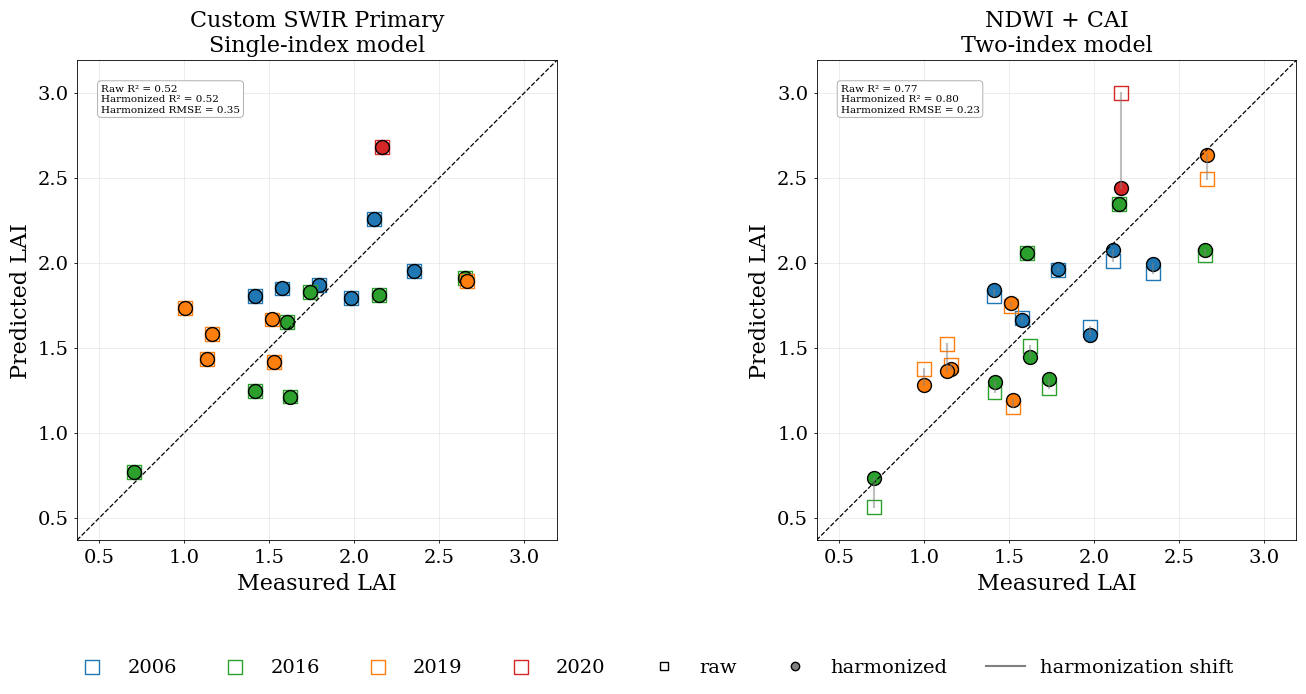

Selected models:
           Features      Form  raw_Train_R2  harmon_Train_R2  raw_LOOCV_R2  harmon_LOOCV_R2
Custom_SWIR_Primary    Linear         0.522            0.522         0.427            0.427
         NDWI + CAI Quadratic         0.772            0.799         0.494            0.670


In [47]:
# -------------------------------------------------------------
# Comparison of best single-index vs best two-index model
# -------------------------------------------------------------


color_mapping = {
    "BY_2006": "#1f77b4",
    "BY_2016": "#2ca02c",
    "BY_2019": "#ff7f0e",
    "BY_2020": "#d62728",
}

dataset_order = ["BY_2006", "BY_2016", "BY_2019", "BY_2020"]

if "dataset" not in plot_data.columns:
    def burn_year_from_plot_id(plot_id):
        plot_id = str(plot_id)
        if plot_id.startswith("GBS06"):
            return "BY_2006"
        if plot_id.startswith("GBS16") or plot_id.startswith("GBS17"):
            return "BY_2016"
        if plot_id.startswith("GBS19"):
            return "BY_2019"
        if plot_id.startswith("GBS20"):
            return "BY_2020"
        return "Unknown"

    plot_data["dataset"] = plot_data["plot_id"].apply(burn_year_from_plot_id)


# Choose best single-index and two-index models

sort_col = "harmon_LOOCV_R2"

pred_u_col = "Preds_U"
pred_c_col = "Preds_C"

display_r2_u_col = "raw_Train_R2"
display_r2_c_col = "harmon_Train_R2"
display_rmse_c_col = "harmon_Train_RMSE"


def clean_feature_label(name):
    return str(name).replace("_", " ")


def clean_features_label(features):
    return " + ".join(clean_feature_label(f) for f in str(features).split(" + "))


best_single = (
    df_all_index_models[df_all_index_models["K"] == 1]
    .sort_values(sort_col, ascending=False)
    .iloc[0]
)

best_multi = (
    df_all_index_models[df_all_index_models["K"] == 2]
    .sort_values(sort_col, ascending=False)
    .iloc[0]
)


def datasets_for_model_row(row):
    feature_names = row["Features"].split(" + ")

    X_u_combo = np.column_stack([raw_indices[name] for name in feature_names])
    X_c_combo = np.column_stack([harmon_indices[name] for name in feature_names])
    y_target = np.asarray(lai_values)

    valid_mask = (
        np.isfinite(X_u_combo).all(axis=1)
        & np.isfinite(X_c_combo).all(axis=1)
        & np.isfinite(y_target)
    )

    return plot_data["dataset"].values[valid_mask]


single_actual = np.asarray(best_single["Actual_Y"])
single_raw = np.asarray(best_single[pred_u_col])
single_harmon = np.asarray(best_single[pred_c_col])
single_datasets = datasets_for_model_row(best_single)

multi_actual = np.asarray(best_multi["Actual_Y"])
multi_raw = np.asarray(best_multi[pred_u_col])
multi_harmon = np.asarray(best_multi[pred_c_col])
multi_datasets = datasets_for_model_row(best_multi)

all_actual = np.concatenate([single_actual, multi_actual])
all_pred = np.concatenate([single_raw, single_harmon, multi_raw, multi_harmon])

min_val = min(np.nanmin(all_actual), np.nanmin(all_pred))
max_val = max(np.nanmax(all_actual), np.nanmax(all_pred))
pad = 0.08 * (max_val - min_val)

axis_min = min_val - pad
axis_max = max_val + pad


# Plot

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

plot_specs = [
    {
        "ax": axes[0],
        "title": f"{clean_features_label(best_single['Features'])}\nSingle-index model",
        "actual": single_actual,
        "raw": single_raw,
        "harmon": single_harmon,
        "datasets": single_datasets,
        "stats": (
            f"Raw R² = {best_single[display_r2_u_col]:.2f}\n"
            f"Harmonized R² = {best_single[display_r2_c_col]:.2f}\n"
            f"Harmonized RMSE = {best_single[display_rmse_c_col]:.2f}"
        ),
    },
    {
        "ax": axes[1],
        "title": f"{clean_features_label(best_multi['Features'])}\nTwo-index model",
        "actual": multi_actual,
        "raw": multi_raw,
        "harmon": multi_harmon,
        "datasets": multi_datasets,
        "stats": (
            f"Raw R² = {best_multi[display_r2_u_col]:.2f}\n"
            f"Harmonized R² = {best_multi[display_r2_c_col]:.2f}\n"
            f"Harmonized RMSE = {best_multi[display_rmse_c_col]:.2f}"
        ),
    },
]

for spec in plot_specs:
    ax = spec["ax"]
    actual = spec["actual"]
    raw = spec["raw"]
    harmon = spec["harmon"]
    datasets = spec["datasets"]

    for y_obs, pred_u, pred_c in zip(actual, raw, harmon):
        ax.plot(
            [y_obs, y_obs],
            [pred_u, pred_c],
            color="gray",
            alpha=0.5
        )

    for ds in dataset_order:
        ds_mask = datasets == ds

        if not np.any(ds_mask):
            continue

        ds_color = color_mapping.get(ds, "black")
        ds_label = ds.replace("BY_", "")

        ax.scatter(
            actual[ds_mask],
            raw[ds_mask],
            facecolors="none",
            edgecolors=ds_color,
            marker="s",
            s=100,
            label=ds_label
        )

        ax.scatter(
            actual[ds_mask],
            harmon[ds_mask],
            facecolors=ds_color,
            edgecolors="black",
            marker="o",
            s=100
        )

    format_1to1_axis(ax, axis_min, axis_max)
    add_stats_box(ax, spec["stats"])

    ax.set_title(spec["title"])
    ax.set_xlabel("Measured LAI")
    ax.set_ylabel("Predicted LAI")

handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))

marker_handles = [
    plt.Line2D(
        [0], [0],
        marker="s",
        linestyle="none",
        markerfacecolor="none",
        markeredgecolor="black",
        label="raw"
    ),
    plt.Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor="gray",
        markeredgecolor="black",
        label="harmonized"
    ),
    plt.Line2D(
        [0], [0],
        color="gray",
        label="harmonization shift"
    ),
]

fig.legend(
    list(by_label.values()) + marker_handles,
    list(by_label.keys()) + ["raw", "harmonized", "harmonization shift"],
    loc="lower center",
    ncol=7,
    frameon=False
)

fig.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()


print("Selected models:")
print(
    pd.DataFrame([
        best_single[[
            "Features", "Form",
            "raw_Train_R2", "harmon_Train_R2",
            "raw_LOOCV_R2", "harmon_LOOCV_R2"
        ]],
        best_multi[[
            "Features", "Form",
            "raw_Train_R2", "harmon_Train_R2",
            "raw_LOOCV_R2", "harmon_LOOCV_R2"
        ]]
    ]).round(3).to_string(index=False)
)

In [48]:
# ----------------------------------------------------------------------
# PHASE 7: Spatial Extrapolation & LAI Trend Analysis
# ------------------------------------------------------------------------


print("\n" + "-"*110)
print("Phase 7: Spatial Extrapolation & LAI Trend Extraction")
print("-"*110)

# 7a. Train final model on full harmonized dataset using best-performing indices
print("Training final NDWI + CAI Quadratic model on harmonized dataset...")

X_train_final = np.column_stack([harmon_indices['NDWI'], harmon_indices['CAI']])
y_train_final = lai_values 

# Filter valid training data
valid_mask = np.isfinite(X_train_final).all(axis=1) & np.isfinite(y_train_final)
X_train_clean, y_train_clean = X_train_final[valid_mask], y_train_final[valid_mask]

# Fit Model
poly_prod = PolynomialFeatures(degree=2, include_bias=False)
X_poly_prod = poly_prod.fit_transform(X_train_clean)

final_lai_model = LinearRegression()
final_lai_model.fit(X_poly_prod, y_train_clean)
print(f"  -> Model Training R²: {final_lai_model.score(X_poly_prod, y_train_clean):.3f}")

# 7b. Extrapolate LAI across AVIRIS-NG flightlines using the trained model
print("\nExtrapolating LAI across AVIRIS-NG flightlines...")

out_dir = "./AVIRIS_Predicted_LAI_Rasters"
os.makedirs(out_dir, exist_ok=True)
extrapolated_tifs = []

# Target wavelengths for NDWI and CAI
target_wls = [860, 1240, 2005, 2100, 2210]
clean_wls = wavelengths.filled(np.nan) if np.ma.isMaskedArray(wavelengths) else np.array(wavelengths)

# Wrap in int() to prevent rasterio 'numpy.int64 is not iterable' error
band_indices = {wl: int(np.argmin(np.abs(clean_wls - wl)) + 1) for wl in target_wls}
eps = 1e-6

for nc_file in raster_files:
    if os.path.exists(nc_file):
        actual_path = nc_file
    elif os.path.exists(os.path.basename(nc_file)):
        actual_path = os.path.basename(nc_file)
    else: continue

    out_tif = os.path.join(out_dir, f"LAI_{os.path.basename(actual_path).replace('.nc', '.tif')}")
    extrapolated_tifs.append(out_tif)
    
    if os.path.exists(out_tif):
        print(f"  -> Loading cached: {os.path.basename(out_tif)}")
        continue

    print(f"  -> Processing: {os.path.basename(actual_path)}")
    netcdf_path = f"NETCDF:{actual_path}:/reflectance/reflectance"
    
    try:
        with rasterio.open(netcdf_path) as src:
            meta = src.meta.copy()
            
            # Read only the 5 required bands
            b = {wl: src.read(band_indices[wl]).astype(float) for wl in target_wls}
            
            # Create valid pixel mask
            valid_pixels = (b[860] > -50) & (b[1240] > -50)
            
            # Calculate Indices
            ndwi = np.zeros_like(b[860])
            cai = np.zeros_like(b[860])
            
            ndwi[valid_pixels] = (b[860][valid_pixels] - b[1240][valid_pixels]) / (b[860][valid_pixels] + b[1240][valid_pixels] + eps)
            cai[valid_pixels] = 0.5 * (b[2005][valid_pixels] + b[2210][valid_pixels]) - b[2100][valid_pixels]
            
            # Predict LAI
            X_map = np.column_stack([ndwi[valid_pixels], cai[valid_pixels]])
            X_map_poly = poly_prod.transform(X_map)
            
            lai_pred = np.full_like(b[860], np.nan)
            lai_pred[valid_pixels] = final_lai_model.predict(X_map_poly)
            
            # Constrain predictions to realistic biological limits
            lai_pred[valid_pixels] = np.clip(lai_pred[valid_pixels], 0.0, 3)
            lai_pred[~valid_pixels] = -9999.0
            
            # Explicitly set driver='GTiff'
            meta.update(
                driver='GTiff',
                count=1, 
                dtype='float32', 
                nodata=-9999.0
            )
            
            with rasterio.open(out_tif, 'w', **meta) as dst:
                dst.write(lai_pred.astype('float32'), 1)
                
    except Exception as e:
        print(f"  [ERROR] Processing {os.path.basename(actual_path)}: {e}")

# 7c. Merge LAI maps and link to Burn Year Shapefile for trend analysis
print("\nMerging LAI maps and linking to Burn Year Shapefile...")

# Mosaic the individual LAI flightlines
src_files_to_mosaic = [rasterio.open(tif) for tif in extrapolated_tifs if os.path.exists(tif)]
if not src_files_to_mosaic:
    raise ValueError("No TIF files were generated or found to mosaic.")

mosaic, out_trans = merge(src_files_to_mosaic, nodata=-9999.0)
mosaic_crs = src_files_to_mosaic[0].crs
for src in src_files_to_mosaic: src.close()

merged_lai_path = os.path.join(out_dir, "Merged_Fynbos_LAI.tif")
out_meta = src_files_to_mosaic[0].meta.copy()

out_meta.update({
    "driver": "GTiff",
    "height": mosaic.shape[1], 
    "width": mosaic.shape[2], 
    "transform": out_trans, 
    "nodata": -9999.0
})

with rasterio.open(merged_lai_path, "w", **out_meta) as dest:
    dest.write(mosaic)

# Load Fire Shapefile
shp_file = './Fire_boundaries_shapes/fire_region_new_CRS.shp'
fire_gdf = gpd.read_file(shp_file)

# Align CRS
if fire_gdf.crs != mosaic_crs:
    print(f"  -> Aligning Fire Boundaries CRS to AVIRIS mosaic...")
    fire_gdf = fire_gdf.to_crs(mosaic_crs)

# Calculate Years Since Fire (Assuming image acquisition in late 2025)
current_year = 2025 
fire_gdf['Years_Since_Fire'] = current_year - fire_gdf['Year']

# Run Zonal Stats
print("  -> Calculating Zonal Statistics (Mean/Median LAI per fire polygon)...")
stats = zonal_stats(fire_gdf, merged_lai_path, stats="mean median count", nodata=-9999.0)

fire_gdf['Mean_LAI'] = [s['mean'] for s in stats]
fire_gdf['Median_LAI'] = [s['median'] for s in stats]
fire_gdf['Valid_Pixels'] = [s['count'] for s in stats]

# Filter valid analysis targets and SORT for the boxplot
fire_analysis_df = fire_gdf[fire_gdf['Valid_Pixels'] >= 10].copy()
fire_analysis_df.dropna(subset=['Mean_LAI'], inplace=True)
fire_analysis_df = fire_analysis_df.sort_values('Years_Since_Fire')


--------------------------------------------------------------------------------------------------------------
Phase 7: Spatial Extrapolation & LAI Trend Extraction
--------------------------------------------------------------------------------------------------------------
Training final NDWI + CAI Quadratic model on harmonized dataset...
  -> Model Training R²: 0.799

Extrapolating LAI across AVIRIS-NG flightlines...
  -> Loading cached: LAI_ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.tif
  -> Loading cached: LAI_ang20231109t062226_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.tif
  -> Loading cached: LAI_ang20231109t062226_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.tif
  -> Loading cached: LAI_ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.tif

Merging LAI maps and linking to Burn Year Shapefile...
  -> Calculating Zonal Statistics (Mean/Median LAI per fire polygon)...



Generating masked spatial map and Box Plot trends...


/var/folders/_z/xfqh2srd4zg69mc724gvhc6m0000gn/T/ipykernel_29091/342488529.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


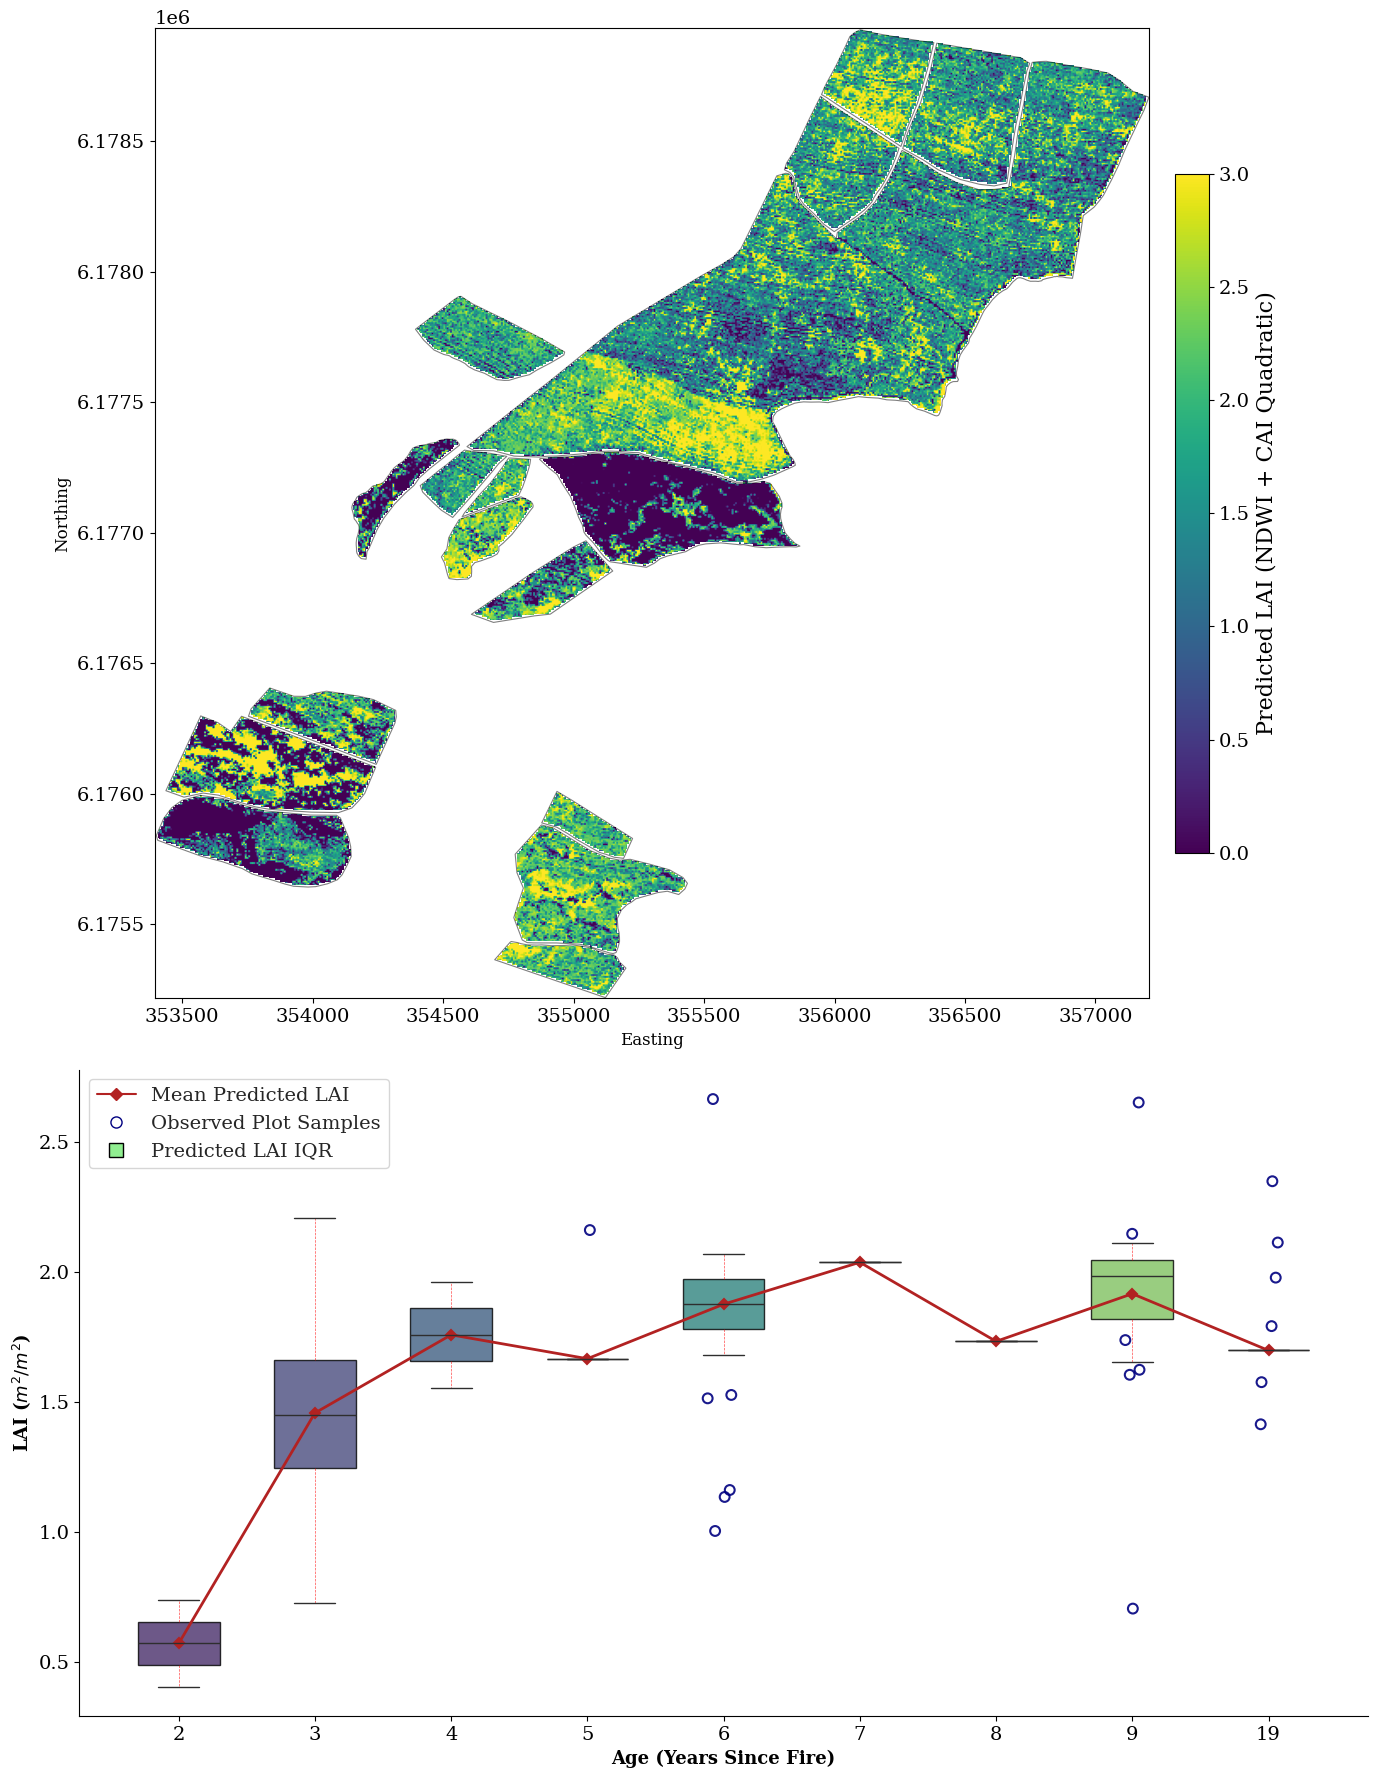


Pipeline Complete! Masked analysis ready for 17 burn polygons.


In [49]:
# 7d. Visualize spatial LAI map and box plot trends with observed sample overlay

from matplotlib.lines import Line2D
from rasterio.mask import mask 

print("\nGenerating masked spatial map and Box Plot trends...")

# Create figure with 2 rows, height ratio 1.5:1 so the map is bigger
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(14, 18), gridspec_kw={'height_ratios': [1.5, 1]})

# SUBPLOT 1: Spatial Map
with rasterio.open(merged_lai_path) as src:
    out_image, out_transform = mask(src, fire_analysis_df.geometry, crop=True, nodata=-9999.0)
    lai_img = out_image[0]
    lai_img = np.where(lai_img == -9999.0, np.nan, lai_img)
    
    height, width = lai_img.shape
    bounds = rasterio.transform.array_bounds(height, width, out_transform)
    extent = [bounds[0], bounds[2], bounds[1], bounds[3]]

img = ax1.imshow(lai_img, extent=extent, cmap='viridis', vmin=0, vmax=3, origin='upper')
plt.colorbar(img, ax=ax1, label='Predicted LAI (NDWI + CAI Quadratic)', shrink=0.7, pad=0.02)

fire_analysis_df.plot(ax=ax1, facecolor='none', edgecolor='black', linewidth=0.8, alpha=0.5)

# ax1.set_title("Predicted LAI (Masked to Burn Regions)", fontsize=16, weight='bold')
ax1.set_xlabel("Easting", fontsize=12)
ax1.set_ylabel("Northing", fontsize=12)
ax1.grid(False)


# SUBPLOT 2: Box Plot of LAI vs. Years Since Fire with Observed Overlay
# 1. Prepare observed plot data
def extract_burn_year(plot_id):
    match = re.search(r'(06|16|19|20)', str(plot_id))
    if match:
        return 2000 + int(match.group(1))
    return np.nan

# Attempt to load original plot samples. Assumes 'lai_gdf' is in memory from earlier phases.
has_obs = False
try:
    lai_obs = lai_gdf.copy()
    lai_obs['Burn_Year'] = lai_obs['plot_id'].apply(extract_burn_year)
    lai_obs['YSF'] = current_year - lai_obs['Burn_Year']
    
    # Identify the correct LAI column name from your dataframe
    obs_lai_col = 'LAI_mean' if 'LAI_mean' in lai_obs.columns else lai_obs.columns[1] 
    
    lai_obs = lai_obs.dropna(subset=['YSF', obs_lai_col]).copy()
    lai_obs = lai_obs[lai_obs['YSF'] >= 0]
    lai_obs['YSF'] = lai_obs['YSF'].astype(int)

    ysf_order = sorted(fire_analysis_df['Years_Since_Fire'].dropna().unique())
    lai_obs = lai_obs[lai_obs['YSF'].isin(ysf_order)].copy()
    has_obs = True
except NameError:
    print("  -> [Note] 'lai_gdf' not found in environment. Plotting predictions without observed overlay.")
    ysf_order = sorted(fire_analysis_df['Years_Since_Fire'].dropna().unique())

# 2. Predicted base plot
sns.set_style("whitegrid")
plt.rc('font', family='serif')

sns.boxplot(
    data=fire_analysis_df,
    x='Years_Since_Fire',
    y='Mean_LAI',
    order=ysf_order,
    palette='viridis',
    showfliers=False,
    width=0.6,
    whiskerprops={'visible': True, 'color': 'red', 'linewidth': 0.5, 'alpha': 0.7, 'linestyle': '--'},
    boxprops=dict(edgecolor='black', alpha=0.8),
    ax=ax2
)

sns.pointplot(
    data=fire_analysis_df,
    x='Years_Since_Fire',
    y='Mean_LAI',
    order=ysf_order,
    estimator='mean',
    color='firebrick',
    markers='D',
    linestyles='-',
    linewidth=2,
    errorbar=None,
    ax=ax2
)

custom_lines = [
    Line2D([0], [0], color='firebrick', marker='D', lw=1.5, label='Mean Predicted LAI'),
    Line2D([0], [0], color='none', marker='s', markerfacecolor='#90EE90',
           markeredgecolor='black', markersize=10, label='Predicted LAI IQR')
]

# 3. Overlay observed samples
if has_obs:
    rng = np.random.default_rng(42)
    for i, ysf in enumerate(ysf_order):
        subset = lai_obs[lai_obs['YSF'] == ysf]
        if len(subset) == 0: continue

        x_jitter = rng.normal(loc=i, scale=0.06, size=len(subset))

        ax2.scatter(
            x_jitter, subset[obs_lai_col],
            s=50, facecolors='none', edgecolors='navy',
            linewidths=1.5, marker='o', alpha=0.9, zorder=5
        )
        
    custom_lines.insert(1, Line2D([0], [0], color='navy', marker='o', linestyle='None',
                                  markerfacecolor='none', markeredgecolor='navy',
                                  markersize=8, label='Observed Plot Samples'))

# ax2.set_title("Fynbos Canopy Recovery (LAI vs. Years Since Fire)", fontsize=14, weight='bold')
ax2.set_xlabel("Age (Years Since Fire)", fontsize=13, fontweight='bold')
ax2.set_ylabel("LAI ($m^2/m^2$)", fontsize=13, fontweight='bold')
ax2.legend(handles=custom_lines, loc='best', frameon=True)
sns.despine(ax=ax2)

plt.tight_layout()
plt.show()

print(f"\nPipeline Complete! Masked analysis ready for {len(fire_analysis_df)} burn polygons.")

Using input LAI raster: ./AVIRIS_Predicted_LAI_Rasters/Merged_Fynbos_LAI.tif


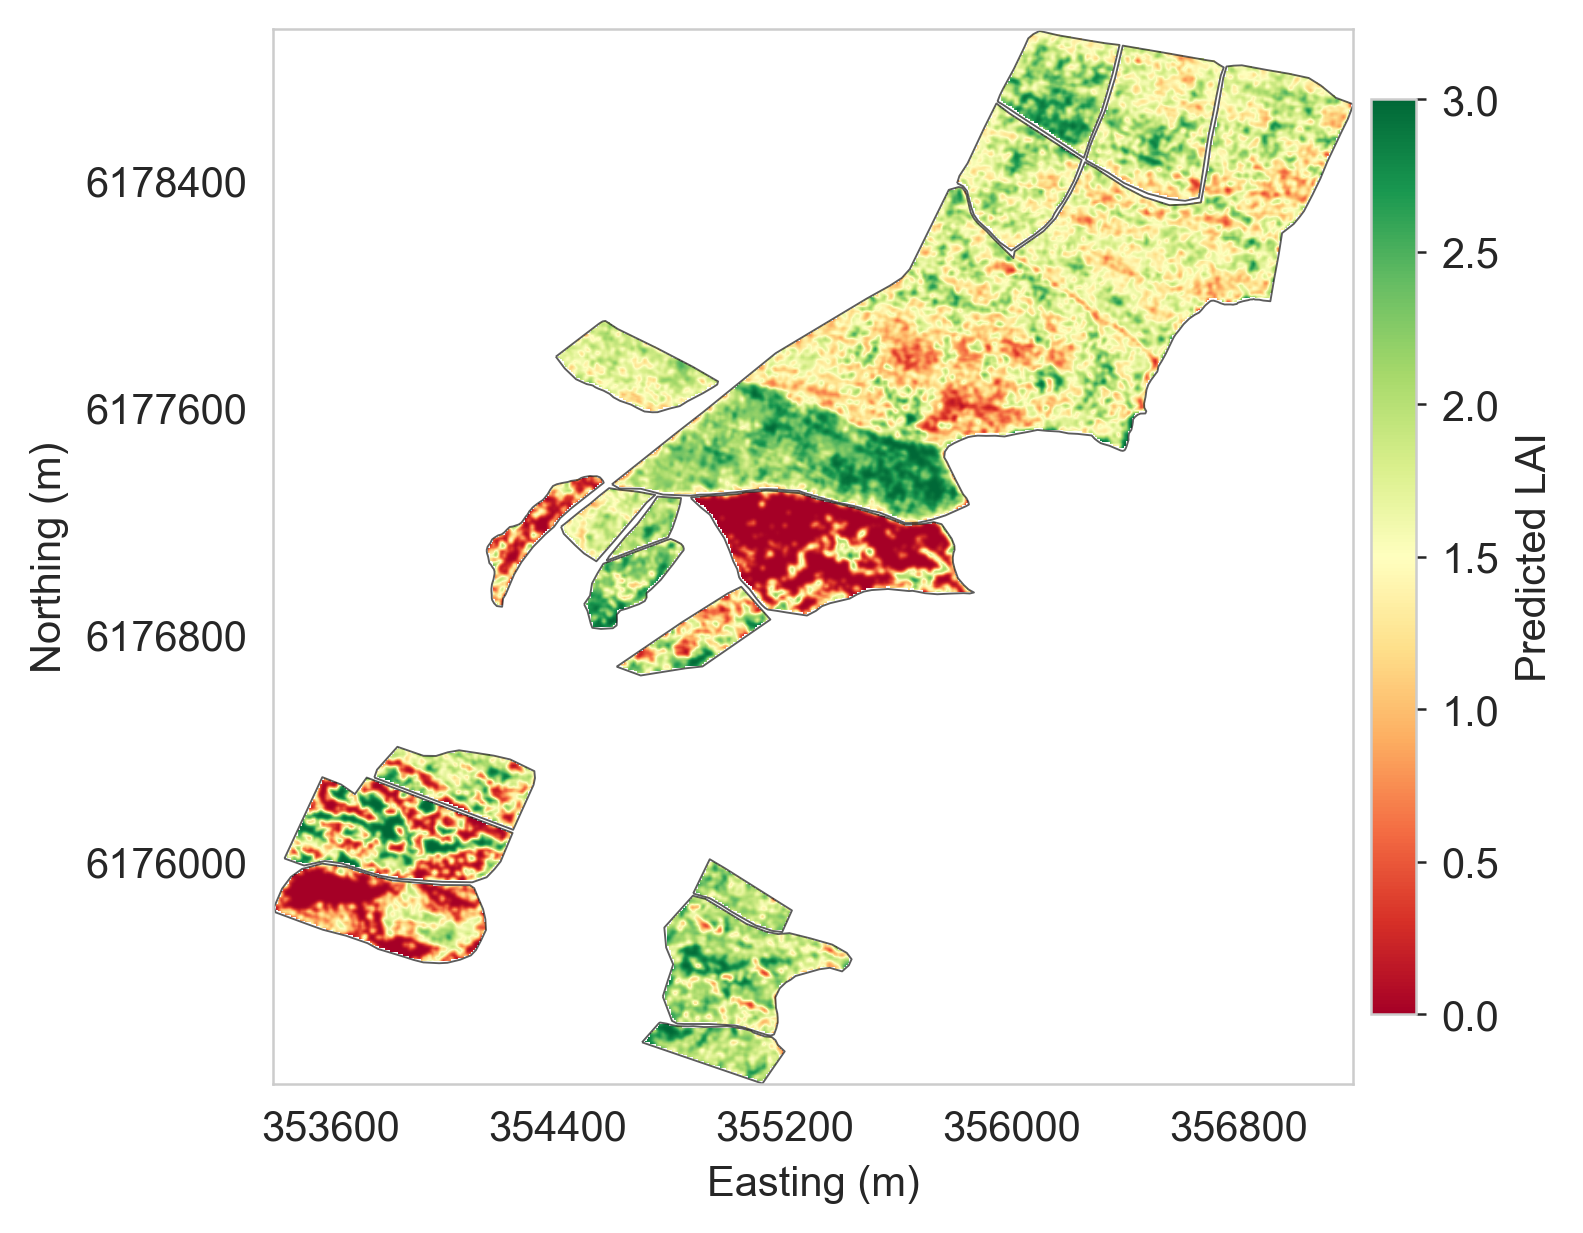

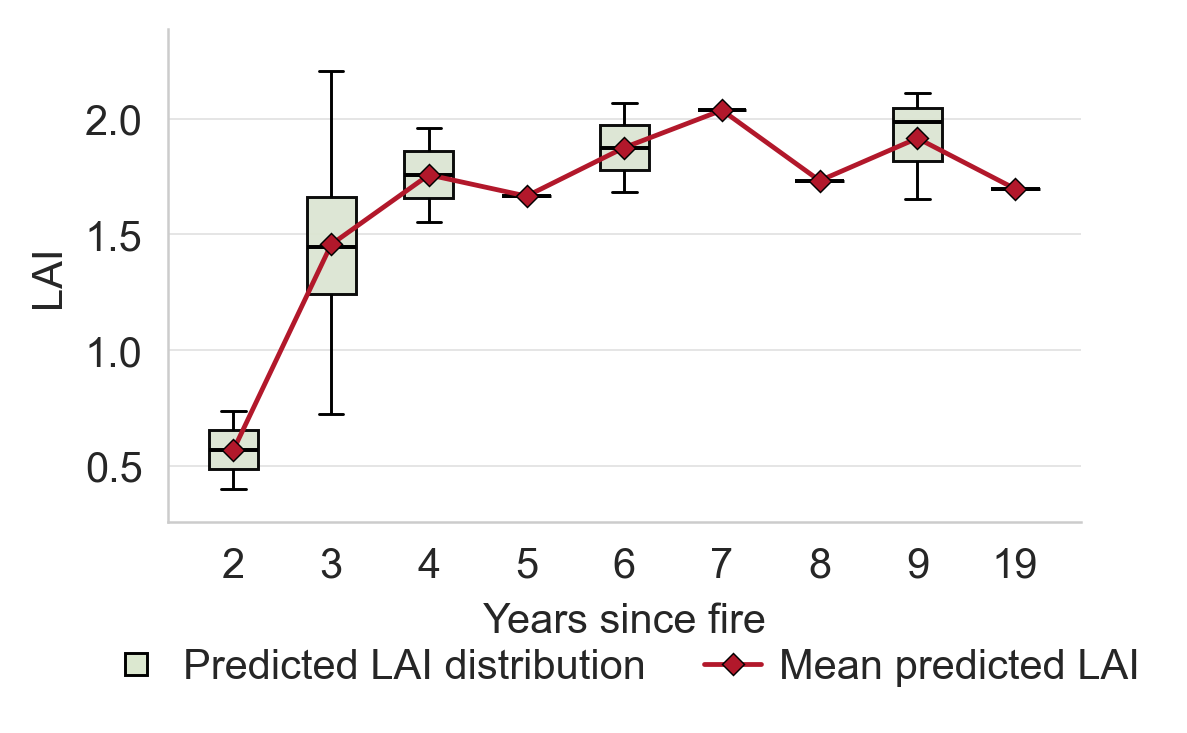

In [50]:
# ---------------------------------------------
# 7D. Predicted LAI map and LAI trend by fire age
# ----------------------------------------------

import matplotlib.ticker as mticker
from scipy.ndimage import gaussian_filter
import matplotlib as mpl

input_lai_path = "./AVIRIS_Predicted_LAI_Rasters/Merged_Fynbos_LAI.tif"

print(f"Using input LAI raster: {input_lai_path}")

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 300,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})

with rasterio.open(input_lai_path) as src:
    out_image, out_transform = mask(
        src,
        fire_analysis_df.geometry,
        crop=True,
        nodata=-9999.0
    )

    lai_img = out_image[0]
    lai_img = np.where(lai_img == -9999.0, np.nan, lai_img)

    height, width = lai_img.shape
    bounds = rasterio.transform.array_bounds(height, width, out_transform)
    extent = [bounds[0], bounds[2], bounds[1], bounds[3]]

# Smooth only for visualization
valid_mask = np.isfinite(lai_img)
lai_for_smoothing = np.where(valid_mask, lai_img, 0.0)
weights = valid_mask.astype(float)

smooth_values = gaussian_filter(lai_for_smoothing, sigma=1)
smooth_weights = gaussian_filter(weights, sigma=1)

lai_img_smooth = smooth_values / np.maximum(smooth_weights, 1e-6)
lai_img_smooth[~valid_mask] = np.nan


# -------------------------------------------
# Plot 1: Predicted LAI map
# -------------------------------------------

fig, ax = plt.subplots(figsize=(5.2, 4.6))

img = ax.imshow(
    lai_img_smooth,
    extent=extent,
    cmap="RdYlGn",
    vmin=0,
    vmax=3,
    origin="upper",
    interpolation="bilinear"
)

fire_analysis_df.boundary.plot(
    ax=ax,
    color="0.15",
    linewidth=0.45,
    alpha=0.75
)

cbar = fig.colorbar(
    img,
    ax=ax,
    orientation="vertical",
    pad=0.015,
    fraction=0.040
)
cbar.set_label("Predicted LAI")
cbar.ax.tick_params(labelsize=10, length=2.5, width=0.6)
cbar.outline.set_linewidth(0.6)

ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal", adjustable="box")
ax.grid(False)
ax.ticklabel_format(style="plain", useOffset=False)
ax.xaxis.set_major_locator(mticker.MaxNLocator(5))
ax.yaxis.set_major_locator(mticker.MaxNLocator(5))
ax.tick_params(axis="both", length=2.5, width=0.6)

for spine in ax.spines.values():
    spine.set_linewidth(0.6)

fig.tight_layout()
plt.show()


# -------------------------------------------
# Plot 2: LAI trend by years since fire
# -------------------------------------------

ysf_order = sorted(fire_analysis_df["Years_Since_Fire"].dropna().astype(int).unique())

plot_df = fire_analysis_df.copy()
plot_df["Years_Since_Fire"] = plot_df["Years_Since_Fire"].astype(int)

fig, ax = plt.subplots(figsize=(3.5, 2.65))

sns.boxplot(
    data=plot_df,
    x="Years_Since_Fire",
    y="Mean_LAI",
    order=ysf_order,
    ax=ax,
    color="#dce8d0",
    width=0.50,
    showfliers=False,
    linewidth=0.70,
    boxprops={
        "edgecolor": "black",
        "linewidth": 0.70,
        "alpha": 0.95,
    },
    whiskerprops={
        "color": "black",
        "linewidth": 0.70,
    },
    capprops={
        "color": "black",
        "linewidth": 0.70,
    },
    medianprops={
        "color": "black",
        "linewidth": 0.95,
    },
)

mean_by_ysf = (
    plot_df
    .groupby("Years_Since_Fire")["Mean_LAI"]
    .mean()
    .reindex(ysf_order)
)

x_pos = np.arange(len(ysf_order))

ax.plot(
    x_pos,
    mean_by_ysf.values,
    color="#b2182b",
    marker="D",
    markersize=3.8,
    markerfacecolor="#b2182b",
    markeredgecolor="black",
    markeredgewidth=0.35,
    linewidth=1.15,
    zorder=4,
)

y_min = plot_df["Mean_LAI"].min()
y_max = plot_df["Mean_LAI"].max()
y_range = y_max - y_min

ax.set_ylim(
    max(0, y_min - 0.08 * y_range),
    y_max + 0.10 * y_range
)

ax.set_xlabel("Years since fire")
ax.set_ylabel("LAI")

ax.grid(True, axis="y", color="0.88", linewidth=0.4)
ax.grid(False, axis="x")
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=2.5, width=0.6)

for spine in ax.spines.values():
    spine.set_linewidth(0.6)

sns.despine(ax=ax)

legend_handles = [
    Line2D(
        [0], [0],
        marker="s",
        linestyle="none",
        markerfacecolor="#dce8d0",
        markeredgecolor="black",
        markeredgewidth=0.70,
        markersize=5.5,
        label="Predicted LAI distribution",
    ),
    Line2D(
        [0], [0],
        color="#b2182b",
        marker="D",
        markerfacecolor="#b2182b",
        markeredgecolor="black",
        markeredgewidth=0.35,
        linewidth=1.15,
        markersize=3.8,
        label="Mean predicted LAI",
    ),
]

ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False,
    handlelength=1.35,
    handletextpad=0.45,
    columnspacing=1.4,
)

fig.subplots_adjust(
    left=0.11,
    right=0.98,
    bottom=0.28,
    top=0.90
)

plt.show()

In [ ]:
print(f"Intercept (β0): {final_lai_model.intercept_:.4f}")
print(f"Coefficients (β1 to β5): {final_lai_model.coef_}")

Intercept (β0): 2.4720
Coefficients (β1 to β5): [ 1.43515344e+01 -4.43484334e+02  1.32210976e+02 -3.50561474e+03
 -4.41036761e+04]



--------------------------------------------------------------------------------------------------------------
Phase 8: Comprehensive Temporal Dynamics of All Indices from Flightlines
--------------------------------------------------------------------------------------------------------------
  -> Masking flightlines and extracting 20 target bands per polygon...
  -> Calculating all 27 indices for extracted burn polygons...
  -> Successfully processed 17 valid burn polygons.
  -> Tracking recovery across 9 age classes: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(19)] YSF.
  -> Generating comprehensive temporal trend grid...


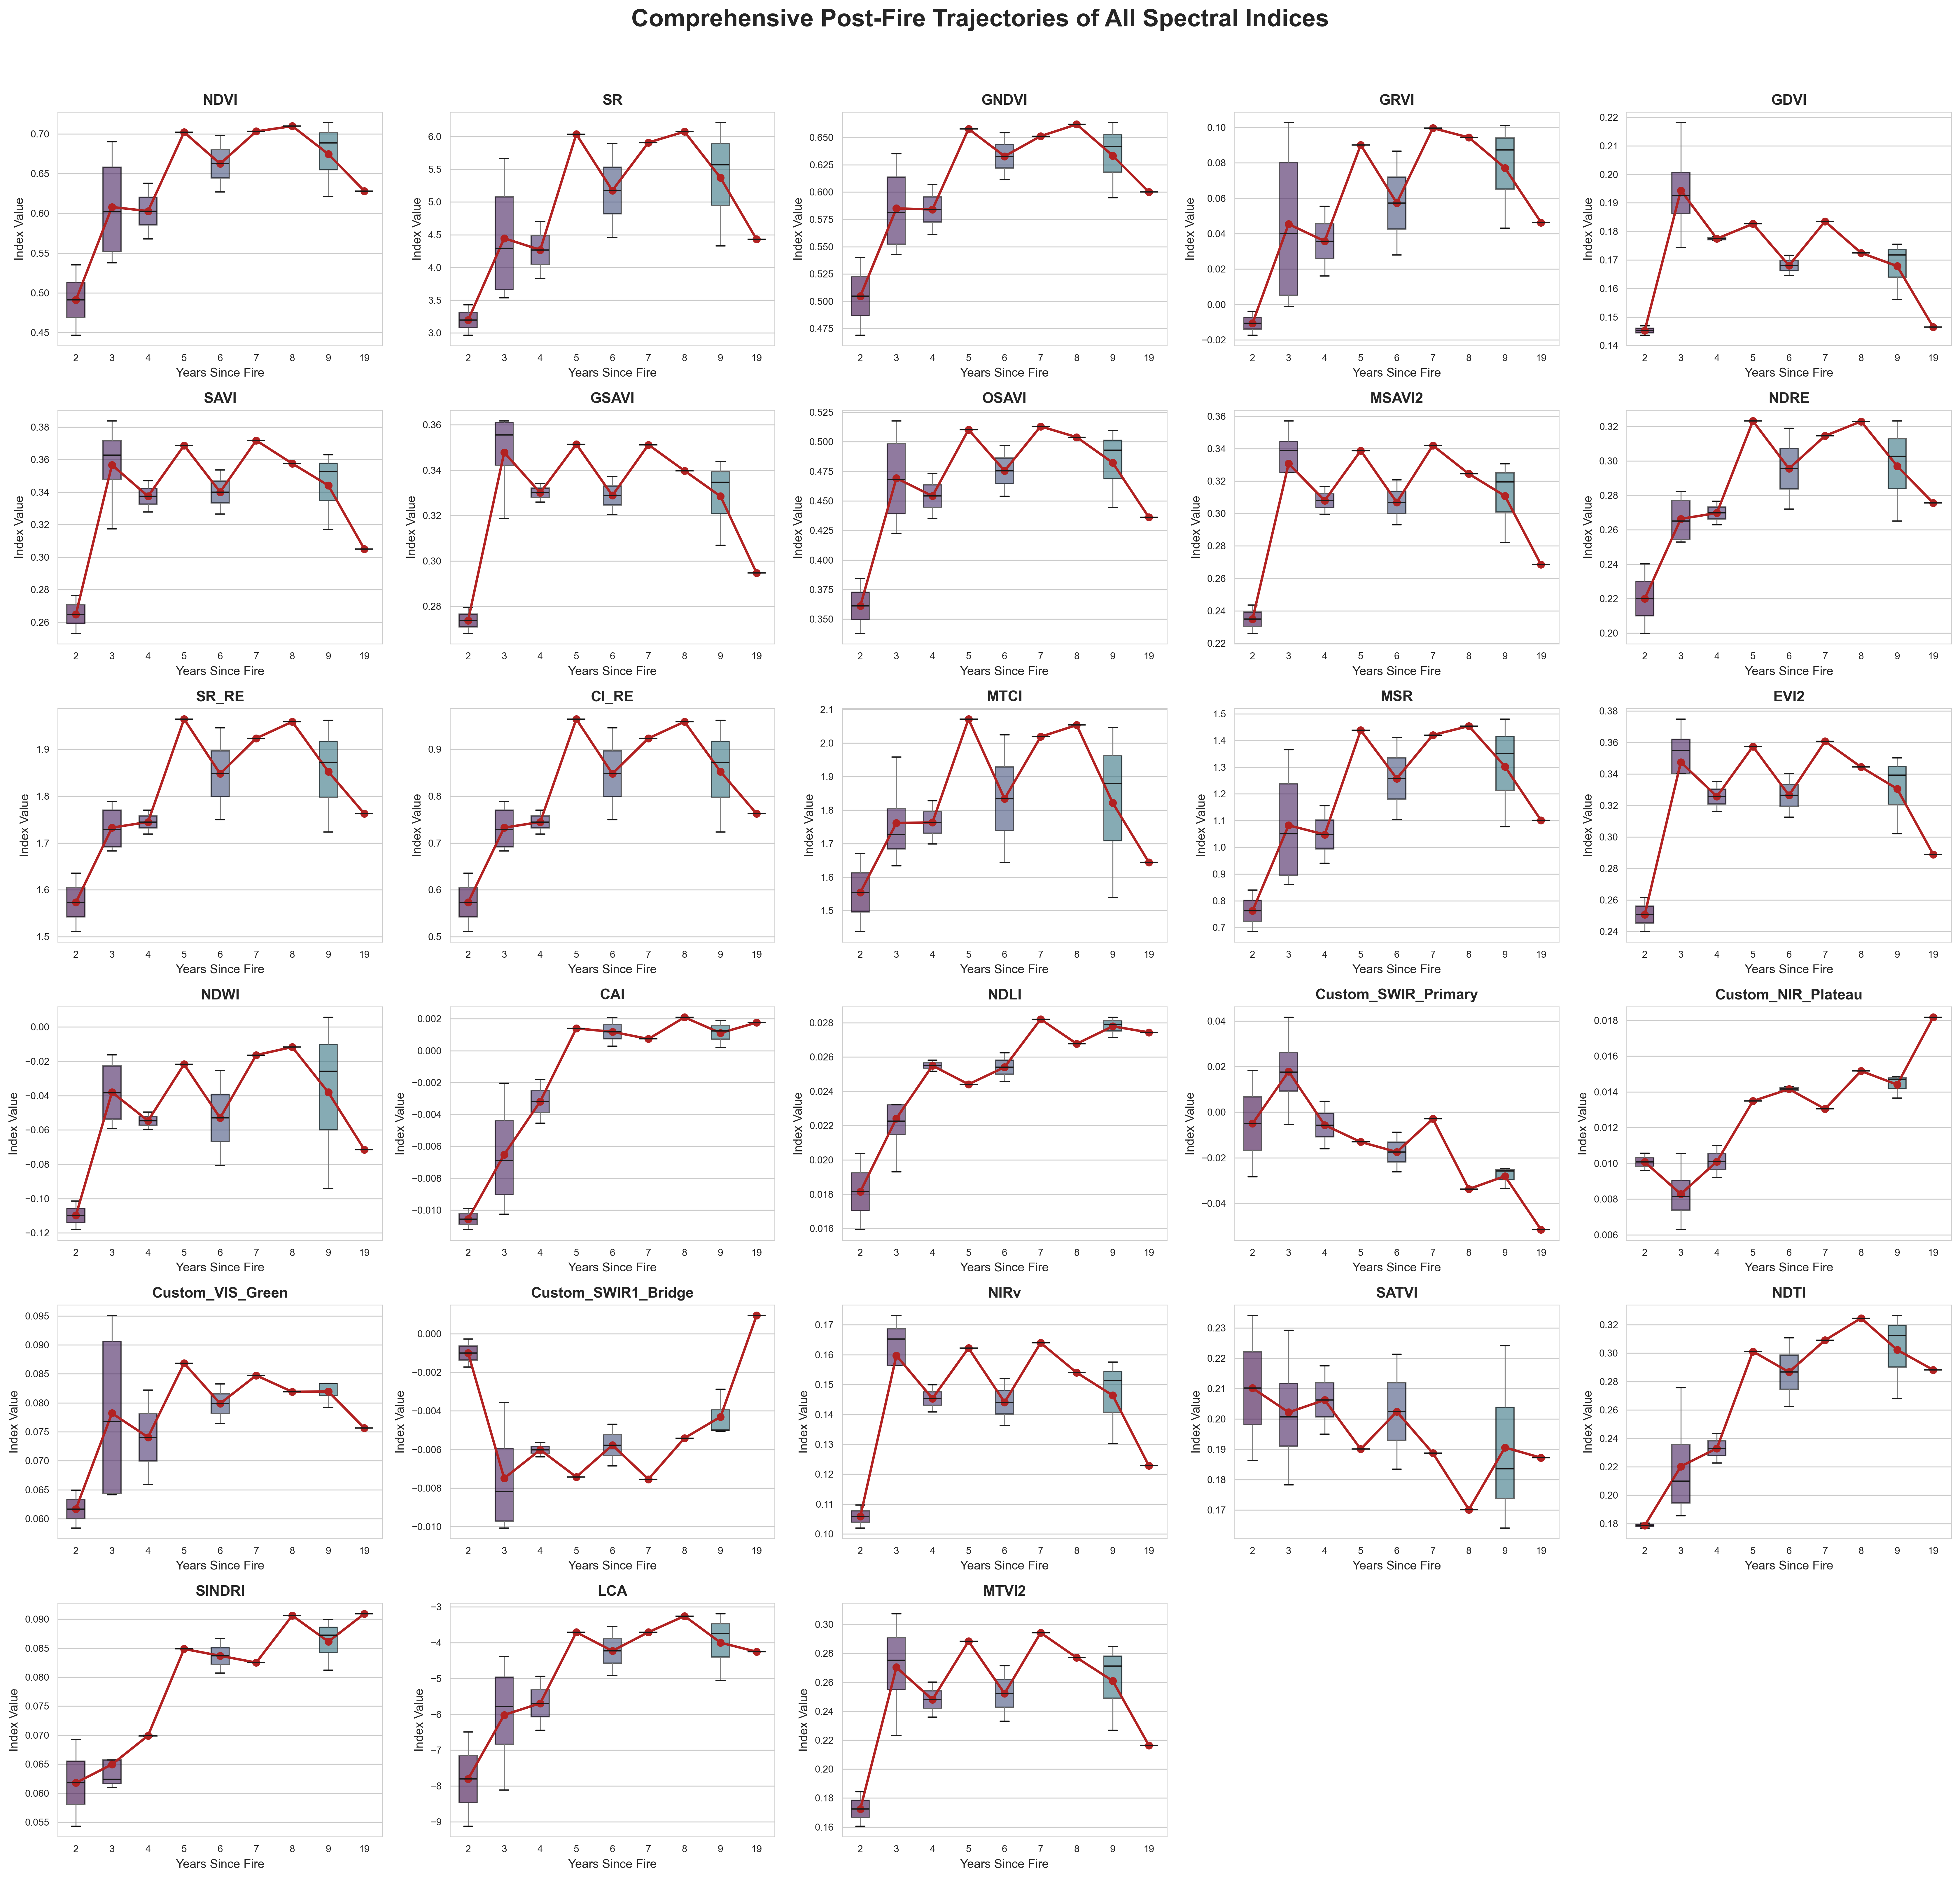

In [51]:
# ------------------------------------------------------------------------
# PHASE 8: Comprehensive Temporal Dynamics of All Indices from Flightlines
# ------------------------------------------------------------------------

from collections import defaultdict

print("\n" + "-"*110)
print("Phase 8: Comprehensive Temporal Dynamics of All Indices from Flightlines")
print("-"*110)

# 1. Ensure Fire Polygons and Temporal Data are ready
if 'Poly_ID' not in fire_gdf.columns:
    fire_gdf['Poly_ID'] = fire_gdf.index

# Safely establish the Years Since Fire column
if 'Years_Since_Fire' not in fire_gdf.columns:
    if 'YSF' in fire_gdf.columns:
        fire_gdf['Years_Since_Fire'] = fire_gdf['YSF']
    elif 'Year' in fire_gdf.columns:
        current_year = 2025 #
        fire_gdf['Years_Since_Fire'] = current_year - fire_gdf['Year']
    else:
        raise KeyError("Could not find 'Year' or 'YSF' column in fire_gdf to calculate recovery age.")

# 2. Define the exact bands needed for 'calculate_all_indices' to prevent RAM overload
w_targets = [
    480, 527.4, 531, 547.4, 550, 570, 670, 681, 709, 720, 754, 800, 850, 860, 
    1240, 1243.6, 1288.7, 1650, 1680, 1729.5, 1749.5, 1750, 2005, 2100, 
    2210, 2260, 2320.5
]

# Map target wavelengths to their 1-based AVIRIS band numbers
clean_wls = wavelengths.filled(np.nan) if np.ma.isMaskedArray(wavelengths) else np.array(wavelengths)
band_indices = {wl: int(np.argmin(np.abs(clean_wls - wl)) + 1) for wl in w_targets}
read_indexes = list(band_indices.values())

print("  -> Masking flightlines and extracting 20 target bands per polygon...")
poly_pixels = defaultdict(list)

# 3. Extract pixels directly from the flightlines
for nc_file in raster_files:
    actual_path = nc_file if os.path.exists(nc_file) else os.path.basename(nc_file)
    if not os.path.exists(actual_path): continue

    try:
        with rasterio.open(f"NETCDF:{actual_path}:/reflectance/reflectance") as src:
            # Align CRS if necessary
            if fire_gdf.crs != src.crs:
                fire_gdf = fire_gdf.to_crs(src.crs)
            
            flightline_box = box(src.bounds.left, src.bounds.bottom, src.bounds.right, src.bounds.top)
            intersecting_polys = fire_gdf[fire_gdf.geometry.intersects(flightline_box)]
            
            for _, row in intersecting_polys.iterrows():
                try:
                    # Mask and read ONLY the 20 target bands
                    out_image, _ = mask(src, [row.geometry], crop=True, indexes=read_indexes)
                    
                    # Reshape from (20, H, W) to (Pixels, 20)
                    n_bands, h, w = out_image.shape
                    pixel_array = out_image.reshape(n_bands, -1).T 
                    
                    # Filter valid pixels (using 860nm [index 11] as a proxy for valid data)
                    valid_mask = pixel_array[:, 11] > -50
                    valid_pixels = pixel_array[valid_mask]
                    
                    if len(valid_pixels) > 10:
                        poly_pixels[row['Poly_ID']].append(valid_pixels)
                except Exception:
                    continue # Polygon geometry might be slightly outside raster bounds
    except Exception as e:
        print(f"  [ERROR] Processing {os.path.basename(actual_path)}: {e}")

# 4. Calculate indices and aggregate by Polygon
print("  -> Calculating all 27 indices for extracted burn polygons...")
aggregated_results = []

for poly_id, pixel_list in poly_pixels.items():
    if not pixel_list:
        continue
        
    # Stack all valid pixels for this polygon
    all_pixels = np.vstack(pixel_list)
    
    # Pass our strictly 20-band array into the existing calculate_all_indices function
    indices_dict = calculate_all_indices(all_pixels, np.array(w_targets))
    
    # Calculate the mean value for every index inside this polygon
    res = {'Poly_ID': poly_id, 'Years_Since_Fire': fire_gdf.loc[poly_id, 'Years_Since_Fire']}
    for idx_name, idx_vals in indices_dict.items():
        res[idx_name] = np.nanmean(idx_vals)
        
    aggregated_results.append(res)

if not aggregated_results:
    raise ValueError("No pixels were extracted from the flightlines. Check CRS alignments and raster extents.")

df_all_trends = pd.DataFrame(aggregated_results)

# Clean and sort the final dataframe
df_all_trends = df_all_trends.dropna(subset=['Years_Since_Fire']).copy()
df_all_trends['Years_Since_Fire'] = df_all_trends['Years_Since_Fire'].astype(int)
df_all_trends = df_all_trends.sort_values('Years_Since_Fire')

ysf_order_all = sorted(df_all_trends['Years_Since_Fire'].unique())
print(f"  -> Successfully processed {len(df_all_trends)} valid burn polygons.")
print(f"  -> Tracking recovery across {len(ysf_order_all)} age classes: {ysf_order_all} YSF.")

## 5. VISUALIZATION

print("  -> Generating comprehensive temporal trend grid...")

# Exclude metadata columns to just plot the indices
indices_to_plot = [col for col in df_all_trends.columns if col not in ['Poly_ID', 'Years_Since_Fire']]
n_indices = len(indices_to_plot)

# Define grid layout (e.g., 5 columns wide)
cols = 5
rows = (n_indices + cols - 1) // cols

sns.set_style("whitegrid")

fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 3.5 * rows))
axes = axes.flatten()

for i, idx_name in enumerate(indices_to_plot):
    ax = axes[i]
    
    # Boxplot for the distribution of the index at each age
    sns.boxplot(
        data=df_all_trends, x='Years_Since_Fire', y=idx_name, order=ysf_order_all,
        ax=ax, hue='Years_Since_Fire', palette='viridis', legend=False, 
        showfliers=False, width=0.5,
        whiskerprops={'linewidth': 0.8, 'color': 'gray'},
        boxprops=dict(alpha=0.6, edgecolor='black')
    )
    
    # Pointplot to highlight the mean trend line
    sns.pointplot(
        data=df_all_trends, x='Years_Since_Fire', y=idx_name, order=ysf_order_all,
        ax=ax, color='firebrick', markers='o', linestyles='-', 
        linewidth=2, errorbar=None
    )
    
    ax.set_title(idx_name, fontsize=12, fontweight='bold')
    ax.set_xlabel("Years Since Fire", fontsize=10)
    ax.set_ylabel("Index Value", fontsize=10)
    ax.tick_params(axis='both', which='major', labelsize=8)

# Remove any empty subplots at the end of the grid
for j in range(n_indices, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Comprehensive Post-Fire Trajectories of All Spectral Indices", 
             fontsize=20, weight='bold', y=1.02)
plt.tight_layout()
plt.show()



Mean raw index value by years since fire:
Years_Since_Fire         2       3       4       5       6       7       8       9       19
Custom_NIR_Plateau   0.0101  0.0083  0.0101  0.0135  0.0142  0.0130  0.0152  0.0144  0.0182
SINDRI               0.0618  0.0650  0.0699  0.0849  0.0837  0.0825  0.0906  0.0861  0.0909
CAI                 -0.0106 -0.0065 -0.0032  0.0014  0.0012  0.0007  0.0021  0.0011  0.0018
NDLI                 0.0182  0.0224  0.0255  0.0244  0.0254  0.0282  0.0268  0.0278  0.0274
NDTI                 0.1788  0.2203  0.2330  0.3012  0.2866  0.3091  0.3246  0.3023  0.2882
LCA                 -7.8055 -6.0159 -5.6908 -3.7101 -4.2308 -3.7080 -3.2576 -4.0002 -4.2540
Custom_SWIR1_Bridge -0.0010 -0.0075 -0.0060 -0.0074 -0.0058 -0.0075 -0.0054 -0.0043  0.0009
GNDVI                0.5047  0.5851  0.5841  0.6579  0.6328  0.6513  0.6620  0.6334  0.6001
NDVI                 0.4910  0.6079  0.6028  0.7020  0.6623  0.7030  0.7097  0.6745  0.6281
NDRE                 0.2200  0.2664  

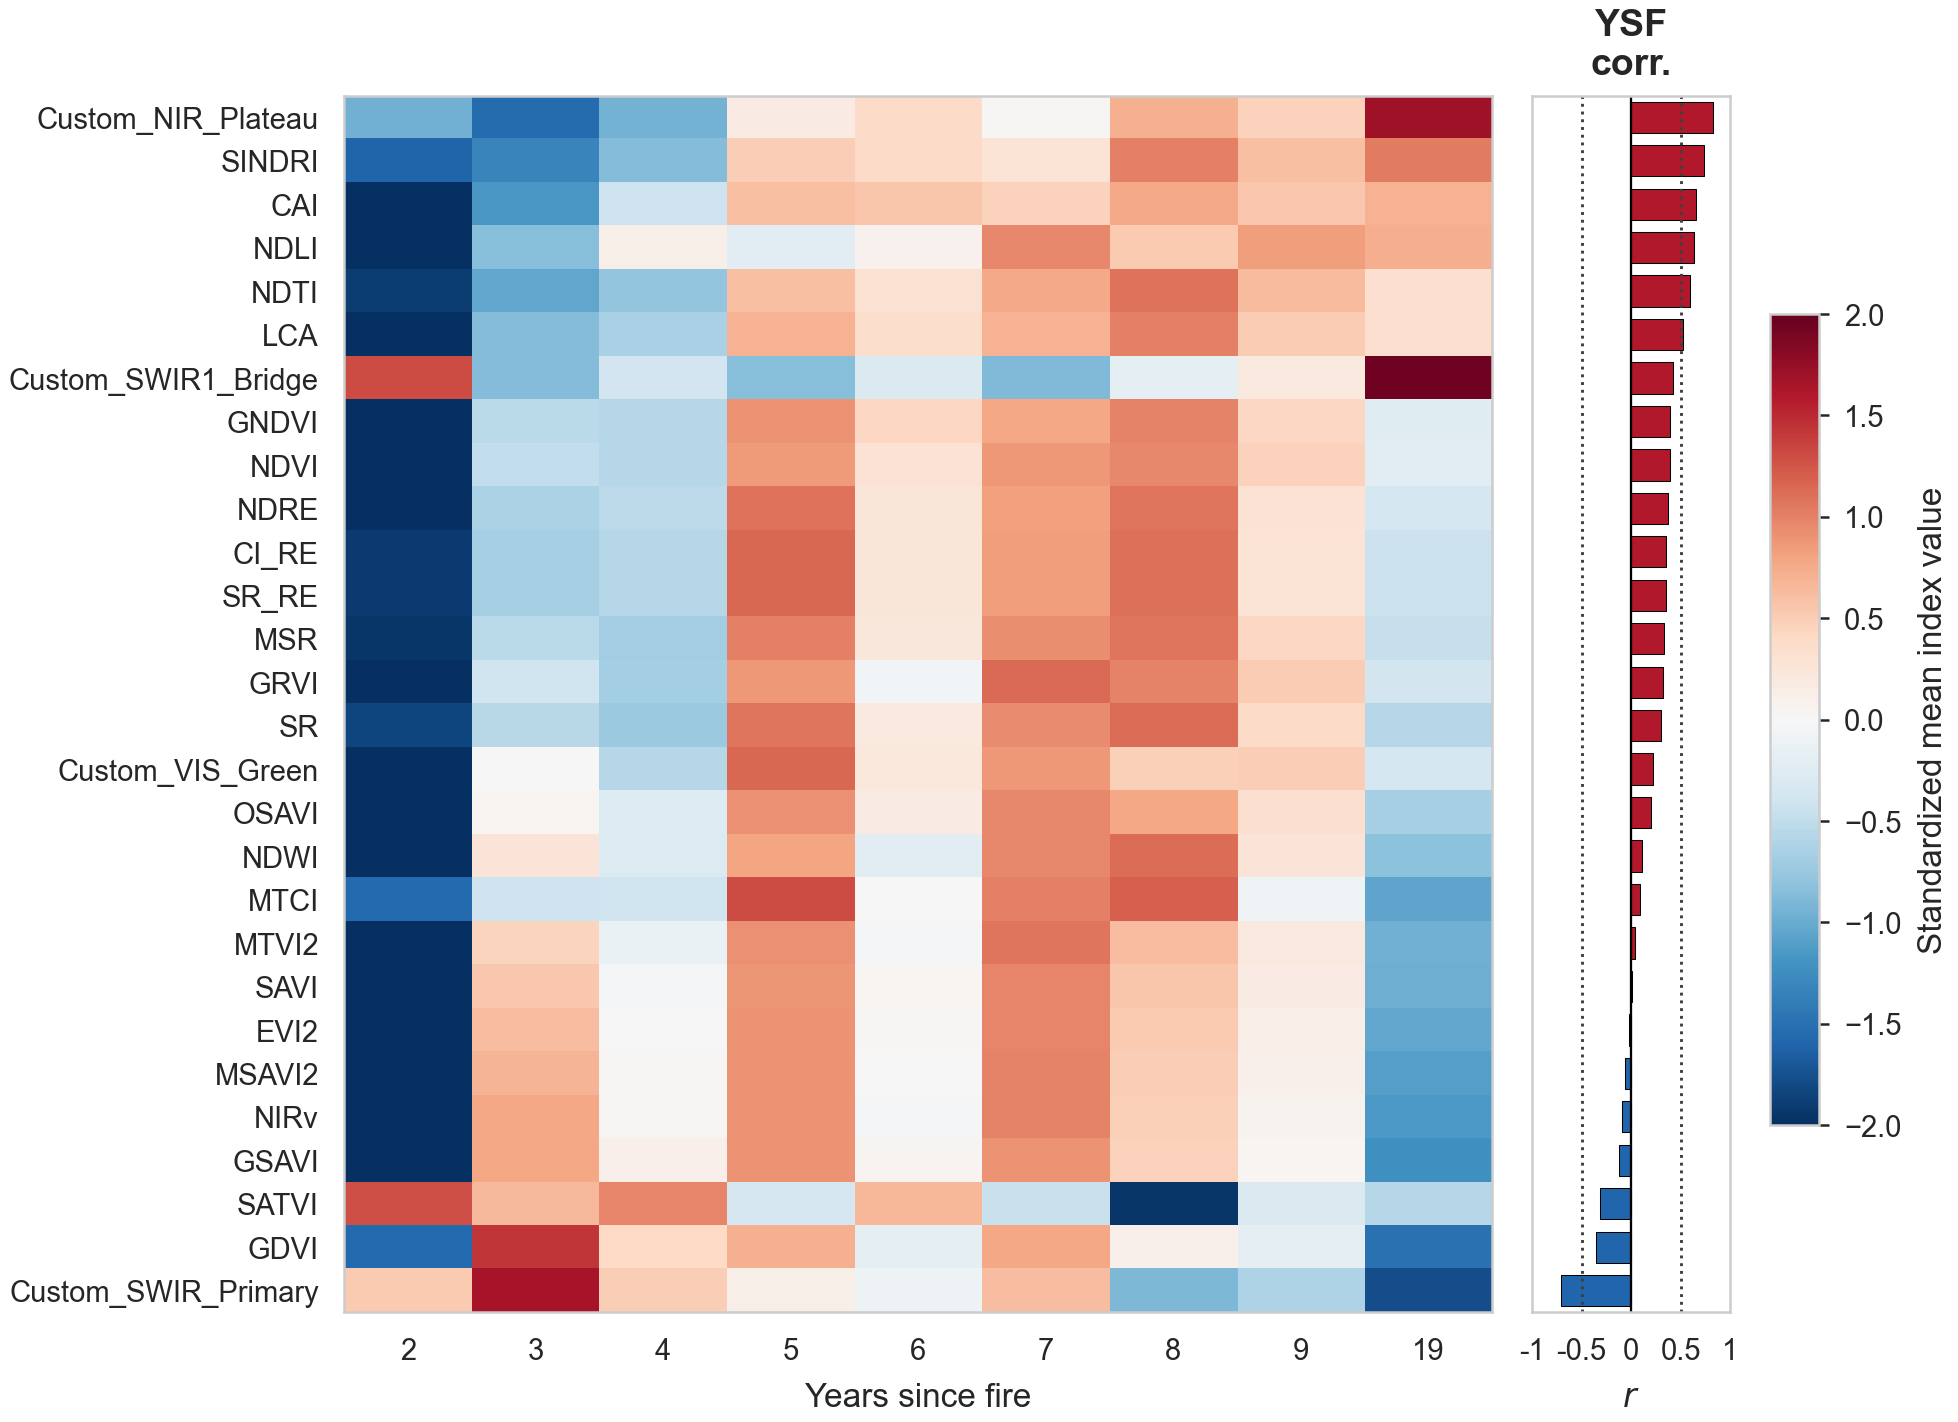

In [52]:
# -------------------------------------------------------------
# Journal style compact temporal dynamics summary
# Heatmap of standardized index trajectories + YSF Pearson correlation
# -------------------------------------------------------------

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 9,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


indices_to_plot = [
    col for col in df_all_trends.columns
    if col not in ["Poly_ID", "Years_Since_Fire"]
]

ysf_order_all = sorted(
    df_all_trends["Years_Since_Fire"]
    .dropna()
    .astype(int)
    .unique()
)

# Mean trajectory per index and fire age
mean_traj = (
    df_all_trends
    .groupby("Years_Since_Fire")[indices_to_plot]
    .mean()
    .reindex(ysf_order_all)
    .T
)

# Remove constant or all-NaN indices
valid_indices = mean_traj.index[
    mean_traj.notna().sum(axis=1).gt(1)
    & mean_traj.std(axis=1, skipna=True).gt(1e-9)
]

mean_traj = mean_traj.loc[valid_indices]

# Z-score each index trajectory so indices with different units are comparable
z_traj = mean_traj.sub(mean_traj.mean(axis=1), axis=0)
z_traj = z_traj.div(mean_traj.std(axis=1), axis=0)

# Pearson correlation of polygon-level index values with years since fire
corr_records = []

for idx in mean_traj.index:
    valid = (
        np.isfinite(df_all_trends[idx])
        & np.isfinite(df_all_trends["Years_Since_Fire"])
    )

    n_valid = int(valid.sum())

    if n_valid < 4:
        r = np.nan
        p_val = np.nan
    else:
        r, p_val = pearsonr(
            df_all_trends.loc[valid, "Years_Since_Fire"],
            df_all_trends.loc[valid, idx]
        )

    corr_records.append({
        "Index": idx,
        "r": r,
        "p": p_val,
        "abs_r": abs(r) if np.isfinite(r) else np.nan,
        "n": n_valid,
    })

corr_df = pd.DataFrame(corr_records).set_index("Index")

# Order indices by Pearson correlation direction
ordered_indices = (
    corr_df
    .loc[z_traj.index]
    .sort_values(["r"], ascending=False)
    .index
)

z_traj = z_traj.loc[ordered_indices]
mean_traj = mean_traj.loc[ordered_indices]
corr_df = corr_df.loc[ordered_indices]


# Print actual mean trajectory values and Pearson correlations

print("\nMean raw index value by years since fire:")
print(
    mean_traj
    .round(4)
    .to_string()
)

print("\nPearson correlation of raw HSI indices with years since fire:")
print(
    corr_df[["r", "p", "n"]]
    .sort_values("r", ascending=False)
    .round(4)
    .to_string()
)

print("\nTop indices by absolute Pearson correlation with years since fire:")
print(
    corr_df
    .sort_values("abs_r", ascending=False)
    [["r", "p", "n"]]
    .head(10)
    .round(4)
    .to_string()
)

# Figure layout

fig = plt.figure(figsize=(6.6, 5.2))

ax_heat = fig.add_axes([0.18, 0.12, 0.58, 0.78])
ax_corr = fig.add_axes([0.78, 0.12, 0.10, 0.78])
cax = fig.add_axes([0.90, 0.24, 0.025, 0.52])

cmap = mpl.cm.RdBu_r
norm = mcolors.TwoSlopeNorm(vmin=-2, vcenter=0, vmax=2)

im = ax_heat.imshow(
    z_traj.values,
    aspect="auto",
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

ax_heat.grid(False)
ax_heat.minorticks_off()
ax_heat.set_xticks(np.arange(len(ysf_order_all)))
ax_heat.set_xticklabels(ysf_order_all)
ax_heat.set_yticks(np.arange(len(z_traj.index)))
ax_heat.set_yticklabels(z_traj.index)

ax_heat.set_xlabel("Years since fire")
ax_heat.set_ylabel("")

ax_heat.tick_params(axis="both", length=2.5, width=0.6)

for spine in ax_heat.spines.values():
    spine.set_linewidth(0.6)

# Correlation side bar
r_vals = corr_df["r"].values

bar_colors = [
    "#b2182b" if val > 0 else "#2166ac"
    for val in r_vals
]

ax_corr.barh(
    np.arange(len(r_vals)),
    r_vals,
    color=bar_colors,
    edgecolor="black",
    linewidth=0.25,
    height=0.72
)

ax_corr.axvline(0, color="black", linewidth=0.55)
ax_corr.axvline(-0.5, color="0.25", linewidth=0.7, linestyle=":")
ax_corr.axvline(0.5, color="0.25", linewidth=0.7, linestyle=":")

ax_corr.set_ylim(ax_heat.get_ylim())
ax_corr.set_xlim(-1, 1)
ax_corr.set_xticks([-1, -0.5, 0, 0.5, 1])
ax_corr.set_xticklabels(["-1", "-0.5", "0", "0.5", "1"])
ax_corr.set_yticks([])
ax_corr.set_xlabel(r"$r$")
ax_corr.set_title("YSF\ncorr.", fontweight="bold", pad=5)

ax_corr.grid(False)
ax_corr.minorticks_off()
ax_corr.tick_params(axis="x", length=2.5, width=0.6)

for spine in ax_corr.spines.values():
    spine.set_linewidth(0.6)

cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Standardized mean index value")
cbar.ax.tick_params(labelsize=7, length=2.5, width=0.6)
cbar.outline.set_linewidth(0.6)
plt.show()